# Notebook 3: Analysis, statistics and figures (all three scenarios)

Reads the saved results of the training notebook (scenarios `all`, `single`, `multi`) and produces every table and figure for the paper. **No model is trained here.**

## Inputs (Add Input -> Your Work -> Notebooks)

| Input | Needed for |
|---|---|
| **Training notebook output(s)** holding `results/all`, `results/single`, `results/multi` (one version that holds all three, or the three versions from different accounts) | everything |
| **Stage 0 output** (the same version used for training) | labels, subset, device, test images |
| **Notebook 1 output** (background removal) | cut-outs for R1 Grad-CAM and the weapon masks |

Settings: **GPU** on (robustness test and Grad-CAM run on it; about 30 to 60 min in total), Internet not needed. Scenarios that are missing are skipped, so the notebook can also be run early on partial results.

## What it produces (`/kaggle/working/analysis/`)

| Section | Scenario | Output |
|---|---|---|
| 2 Dataset | | `tables/T1_*`: images per class, split, subset and device |
| 3 to 7 Per scenario | all, single, multi | `<scenario>/tables/T2..T6`, `<scenario>/figures/F1..F6`: ablation, background, model comparison, per-class F1, confusion matrix, Grad-CAM |
| 8 Scenario comparison and cross-test | all three | `tables/T7_scenarios`, `tables/T8_cross_condition`, `figures/F7_cross_condition` |
| 4b Foundation baseline | all, single, multi | `tables/T4b_foundation_baseline`: frozen DINOv2 + logistic regression vs the best fine-tuned model |
| 9 Device bias | all | `tables/T9_minority_device`, `tables/T10*_cross_device` (four approaches), `figures/F8*` |
| 10 Robustness | all | `tables/T11_robustness*`, `figures/F9_robustness` |
| 11 Calibration | all | `tables/T12_calibration`, `figures/F10_reliability` |
| 12 Speed and size | all | `tables/T13_speed_size` |
| 13 Key numbers | | `key_numbers.md`: the main results in sentence form |

All tables are saved as `.csv` and `.tex`.

**Statistics:** pipelines and models trained on the same 5 folds are compared with paired t-tests on the fold scores (95% CI of the difference), Holm-corrected for multiple comparisons. On the test set: exact McNemar tests and bootstrap 95% confidence intervals. Per-group accuracies use Wilson 95% intervals; group differences use Fisher's exact test.

## 1. Setup and inputs

In [1]:
import os, io, json, math, time, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import cv2
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
from PIL import Image
from scipy import stats, optimize
from sklearn.metrics import f1_score, accuracy_score, confusion_matrix
import torch, timm
import torch.nn.functional as F_

warnings.filterwarnings("ignore", category=UserWarning)
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
print("device:", DEVICE)

# ---- settings ----
REFERENCE_MODEL = "resnet50"     # model used for the full K1..R9 ablation
N_BOOT = 2000                     # bootstrap resamples for test-set confidence intervals
CAM_IMAGES_PER_CLASS = 1          # rows per class in the Grad-CAM figure
ROBUST_FOLDS = [0]                # fold models used in the robustness test ([0, 1, 2, 3, 4] = full ensemble, 5x slower)
SEVERITIES = [1, 2, 3, 4, 5]
ECE_BINS = 15
CROSS_DEVICE_TRAIN = "iPhone 14"
SEED = 42
SCENARIOS = ["all", "single", "multi"]
LP_MODEL = "vit_small_patch14_dinov2.lvd142m"   # foundation-model baseline (frozen features + logistic regression)

ON_KAGGLE = Path("/kaggle/input").is_dir()
INPUT_ROOT = Path("/kaggle/input") if ON_KAGGLE else Path(r"H:\BD Weapon Inputs")
OUT = (Path("/kaggle/working") if ON_KAGGLE else Path(r"H:\BD Weapon Analysis")) / "analysis"
TAB, FIG = OUT / "tables", OUT / "figures"
for d in (TAB, FIG):
    d.mkdir(parents=True, exist_ok=True)

def walk_find(base, predicate, skip=("standardized", "cutouts", "masks", "figures", "weights")):
    for dirpath, dirnames, filenames in os.walk(base, followlinks=True):
        hit = predicate(Path(dirpath), filenames)
        if hit:
            return hit
        dirnames[:] = [x for x in dirnames if x not in skip]
    return None

RESDIRS = {}
for sc in SCENARIOS:
    d = walk_find(INPUT_ROOT, lambda d, f, sc=sc: d if ("summary_all.csv" in f and d.name == sc
                                                       and d.parent.name == "results") else None)
    if d:
        RESDIRS[sc] = d
STAGE0 = walk_find(INPUT_ROOT, lambda d, f: d.parent if ("manifest.csv" in f and d.name == "metadata"
                                                        and d.parent.name == "stage0") else None)
BGR = walk_find(INPUT_ROOT, lambda d, f: d if ("mask_manifest.csv" in f and d.name == "bg_removed") else None)
assert RESDIRS, "No training results found. Add Input -> Your Work -> the training notebook (latest version)."
assert STAGE0, "Stage 0 output not found. Add Input -> Your Work -> stage0_device_split."
for sc, d in RESDIRS.items():
    print(f"results [{sc:6s}]:", d)
print("missing scenarios:", [s for s in SCENARIOS if s not in RESDIRS] or "none")
print("stage 0   :", STAGE0)
print("notebook 1:", BGR)

CLASS_MAP = json.loads((STAGE0 / "metadata" / "class_map.json").read_text())
CLASSES = sorted(CLASS_MAP, key=CLASS_MAP.get)
NC = len(CLASSES)
manifest = pd.read_csv(STAGE0 / "metadata" / "manifest.csv", dtype={"image_id": str})
# capture device: from the manifest (new Stage 0) or, for older Stage 0 outputs, from the camera EXIF in inventory.csv
DEVICE_NAMES = {"apple iphone 14": "iPhone 14", "xiaomi redmi note 15 5g": "Redmi Note 15", "samsung galaxy m14": "Galaxy M14"}
NO_EXIF_DEVICE = "WhatsApp (no camera EXIF)"
def add_device(man, stage0):
    if "device" in man:
        return man, "manifest"
    inv = stage0 / "metadata" / "inventory.csv"
    if inv.exists():
        cam = pd.read_csv(inv, dtype={"image_id": str}, usecols=lambda c: c in ("image_id", "camera"))
        if "camera" in cam:
            cam = cam.drop_duplicates("image_id")
            def dev(c):
                c2 = " ".join(str(c).lower().split()) if isinstance(c, str) else ""
                return DEVICE_NAMES.get(c2, str(c).strip()) if c2 else NO_EXIF_DEVICE
            man = man.merge(cam, on="image_id", how="left")
            man["device"] = man.camera.map(dev)
            return man.drop(columns="camera"), "inventory.csv (camera EXIF)"
    man["device"] = "unknown"
    return man, "not available"
manifest["y"] = manifest.label.map(CLASS_MAP)
manifest, dev_src = add_device(manifest, STAGE0)
print("device column from:", dev_src)
if BGR:
    mm = pd.read_csv(BGR / "mask_manifest.csv", dtype={"image_id": str})
    manifest = manifest.merge(mm[["image_id", "cutout_path", "mask_path", "mask_status"]], on="image_id", how="left")

SUMMARY = {sc: pd.read_csv(d / "summary_all.csv").drop_duplicates(["model", "pipeline"], keep="last")
           for sc, d in RESDIRS.items()}
for sc, s in SUMMARY.items():
    print(f"{sc}: {len(s)} finished runs, models {sorted(s.model.unique())}")
import hashlib
sig = hashlib.sha1(manifest.sort_values("image_id")[["image_id", "split", "fold"]].to_csv(index=False).encode()).hexdigest()[:16]
for sc, d in RESDIRS.items():
    f = d / "split_signature.txt"
    if f.exists():
        assert f.read_text().strip() == sig, (f"Scenario '{sc}' was trained on a different Stage 0 split than the "
                                              "attached Stage 0 output. Attach the Stage 0 version used in training.")

device: cuda
results [all   ]: /kaggle/input/notebooks/arnicasarker/nb2-training-scenarios/results/all
results [single]: /kaggle/input/notebooks/arnicasarker/nb2-training-scenarios/results/single
results [multi ]: /kaggle/input/notebooks/arnicasarker/nb2-training-scenarios/results/multi
missing scenarios: none
stage 0   : /kaggle/input/notebooks/arnicasarker/stage0-single-multi-3parts/stage0
notebook 1: /kaggle/input/notebooks/arnicasarker/nb1-background-removal/bg_removed
device column from: inventory.csv (camera EXIF)
all: 33 finished runs, models ['convnext_tiny', 'efficientnet_b0', 'resnet50', 'vit_small_patch14_dinov2.lvd142m', 'vit_small_patch16_224']
single: 29 finished runs, models ['convnext_tiny', 'efficientnet_b0', 'resnet50', 'vit_small_patch14_dinov2.lvd142m', 'vit_small_patch16_224']
multi: 29 finished runs, models ['convnext_tiny', 'efficientnet_b0', 'resnet50', 'vit_small_patch14_dinov2.lvd142m', 'vit_small_patch16_224']


In [2]:
# ---- statistics helpers ----
def fold_scores(sc, model, pipe):
    p = RESDIRS[sc] / model / pipe / "fold_metrics.csv"
    return pd.read_csv(p).set_index("fold").macro_f1 if p.exists() else None

def paired(sc, model_a, pipe_a, model_b, pipe_b):
    a, b = fold_scores(sc, model_a, pipe_a), fold_scores(sc, model_b, pipe_b)
    if a is None or b is None:
        return None
    common = a.index.intersection(b.index)
    a, b = a[common].to_numpy(), b[common].to_numpy()
    d = a - b; n = len(d)
    if n > 1 and d.std(ddof=1) > 0:
        p = stats.ttest_rel(a, b).pvalue
        half = stats.t.ppf(0.975, n - 1) * d.std(ddof=1) / math.sqrt(n)
    else:
        half, p = float("nan"), float("nan")
    return {"mean_a": a.mean(), "std_a": a.std(ddof=1) if n > 1 else 0.0, "mean_b": b.mean(),
            "diff": d.mean(), "ci_low": d.mean() - half, "ci_high": d.mean() + half,
            "wins": f"{int((d > 0).sum())}/{n}", "p": p}

def holm(pvals):
    p = np.asarray(pvals, dtype=float); out = np.full_like(p, np.nan); ok = ~np.isnan(p)
    if not ok.any():
        return out
    idx = np.argsort(p[ok]); m = ok.sum()
    adj = np.maximum.accumulate((m - np.arange(m)) * p[ok][idx]).clip(max=1)
    tmp = np.empty(m); tmp[idx] = adj; out[ok] = tmp
    return out

def load_preds(sc, model, pipe, kind="test"):
    p = RESDIRS[sc] / model / pipe / f"{kind}_predictions.csv"
    return pd.read_csv(p, dtype={"image_id": str}) if p.exists() else None

def macro_f1(y, pred):
    return f1_score(y, pred, average="macro", labels=range(NC), zero_division=0)

def per_class_prf(df):
    # per-class precision, recall, F1 and how often each class was predicted (shows "sink" classes)
    from sklearn.metrics import precision_recall_fscore_support
    p, r, f, n = precision_recall_fscore_support(df.y, df.pred, labels=range(NC), zero_division=0)
    pred_n = np.bincount(df.pred, minlength=NC)
    return pd.DataFrame({"class": CLASSES, "true_images": n, "predicted_as_this_class": pred_n,
                         "precision": p, "recall": r, "f1": f})

def bootstrap_f1(y, pred, n=N_BOOT, seed=SEED):
    y, pred = np.asarray(y), np.asarray(pred)
    rng = np.random.default_rng(seed)
    vals = [macro_f1(y[i], pred[i]) for i in (rng.integers(0, len(y), len(y)) for _ in range(n))]
    return np.percentile(vals, [2.5, 97.5])

def mcnemar_exact(y, pa, pb):
    a_ok, b_ok = pa == y, pb == y
    n01, n10 = int((a_ok & ~b_ok).sum()), int((~a_ok & b_ok).sum())
    p = stats.binomtest(min(n01, n10), n01 + n10, 0.5).pvalue if n01 + n10 else 1.0
    return n01, n10, p

def wilson(k, n, z=1.96):
    if n == 0:
        return (np.nan, np.nan)
    p = k / n; den = 1 + z * z / n
    c = (p + z * z / (2 * n)) / den; h = z * math.sqrt(p * (1 - p) / n + z * z / (4 * n * n)) / den
    lo, hi = max(0.0, c - h), min(1.0, c + h)
    return (min(lo, p), max(hi, p))        # guard against rounding at p = 0 or 1

def save_table(df, name, tab=None):
    tab = tab or TAB
    tab.mkdir(parents=True, exist_ok=True)
    df.to_csv(tab / f"{name}.csv", index=False)
    try:
        (tab / f"{name}.tex").write_text(df.to_latex(index=False, float_format="%.3f"))
    except Exception:
        pass
    display(df)

# chart palette (validated categorical order; text stays in neutral ink)
BLUE, ORANGE, AQUA, YELLOW = "#2a78d6", "#eb6834", "#1baf7a", "#eda100"
CAT = [BLUE, ORANGE, AQUA, YELLOW, "#8a5cd6", "#d64f8a"]
INK, INK2, GRID = "#0b0b0b", "#52514e", "#e4e3df"
SEQ = LinearSegmentedColormap.from_list("seq_blue", ["#fcfcfb", "#cde2fb", "#86b6ef", "#3987e5", "#1c5cab", "#0d366b"])
plt.rcParams.update({"axes.edgecolor": INK2, "axes.labelcolor": INK, "xtick.color": INK2, "ytick.color": INK2,
                     "axes.spines.top": False, "axes.spines.right": False, "font.size": 10,
                     "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.8, "axes.axisbelow": True,
                     "figure.facecolor": "white", "axes.facecolor": "white", "savefig.dpi": 200})

In [3]:
# ---- image preparation and model loading: identical to the training notebook ----
PAD_GRAY = 128
IMAGENET_MEAN, IMAGENET_STD = [0.485, 0.456, 0.406], [0.229, 0.224, 0.225]

def clahe_rgb(rgb):
    lab = cv2.cvtColor(rgb, cv2.COLOR_RGB2LAB)
    lab[..., 0] = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8, 8)).apply(lab[..., 0])
    return cv2.cvtColor(lab, cv2.COLOR_LAB2RGB)

def geometric(img, size, res, pad=PAD_GRAY):
    h, w = img.shape[:2]
    if size == "stretch":
        return cv2.resize(img, (res, res), interpolation=cv2.INTER_AREA)
    s = res / max(h, w)
    nh, nw = max(1, round(h * s)), max(1, round(w * s))
    small = cv2.resize(img, (nw, nh), interpolation=cv2.INTER_AREA if s < 1 else cv2.INTER_CUBIC)
    out = np.full((res, res) + img.shape[2:], pad, img.dtype)
    t, l = (res - nh) // 2, (res - nw) // 2
    out[t:t + nh, l:l + nw] = small
    return out

def convert_color(rgb, color):
    if color == "gray":
        return np.repeat(cv2.cvtColor(rgb, cv2.COLOR_RGB2GRAY)[..., None], 3, axis=2)
    if color == "hsv":
        return cv2.cvtColor(rgb, cv2.COLOR_RGB2HSV_FULL)
    if color == "lab":
        return cv2.cvtColor(rgb, cv2.COLOR_RGB2LAB)
    return rgb

def pipe_cfg(sc, model, pipe):
    s = SUMMARY[sc]; s = s[(s.model == model) & (s.pipeline == pipe)].iloc[0]
    return {"bg": s.cfg_bg, "size": s.cfg_size, "res": int(s.cfg_res), "aug": s.cfg_aug, "color": s.cfg_color,
            "tta": bool(s.cfg_tta) if "cfg_tta" in s else False}

def load_input(row, cfg):
    # model input before colour conversion: background choice, CLAHE, resize (uint8, res x res x 3)
    src = BGR / row.cutout_path if cfg["bg"] == "removed" else STAGE0 / row.path
    rgb = np.asarray(Image.open(src).convert("RGB"))
    if cfg["color"] == "clahe":
        rgb = clahe_rgb(rgb)
    return geometric(rgb, cfg["size"], cfg["res"])

def has_w(sc, model, pipe, fold=0):
    return (RESDIRS[sc] / model / pipe / "weights" / f"fold{fold}.pt").exists()

def load_net(sc, model, pipe, fold=0):
    cfg = pipe_cfg(sc, model, pipe)
    kw = dict(pretrained=False, num_classes=NC)
    if model.startswith(("vit", "deit", "swin")):
        kw["img_size"] = cfg["res"]
    net = timm.create_model(model, **kw)
    wdir = RESDIRS[sc] / model / pipe / "weights"
    sd = torch.load(wdir / f"fold{fold}.pt", map_location="cpu")
    net.load_state_dict({k: v.float() for k, v in sd.items()})
    norm = json.loads((wdir / "norm.json").read_text()).get(str(fold)) if (wdir / "norm.json").exists() else None
    mean, std = (norm["mean"], norm["std"]) if norm else (IMAGENET_MEAN, IMAGENET_STD)
    return net.eval().to(DEVICE), {**cfg, "mean": np.array(mean), "std": np.array(std)}

def to_tensor(imgs, cfg):
    x = np.stack([convert_color(np.ascontiguousarray(im), cfg["color"]) for im in imgs]).astype(np.float32) / 255
    x = (x - cfg["mean"]) / cfg["std"]
    return torch.from_numpy(x.transpose(0, 3, 1, 2)).float()

@torch.no_grad()
def predict_arrays(net, cfg, imgs, batch=64):
    out = []
    for i in range(0, len(imgs), batch):
        chunk = imgs[i:i + batch]
        views = [chunk] + ([[im[:, ::-1] for im in chunk]] if cfg["tta"] else [])
        p = 0
        for v in views:
            with torch.autocast(device_type=DEVICE, enabled=(DEVICE == "cuda")):
                p = p + F_.softmax(net(to_tensor(v, cfg).to(DEVICE)).float(), 1).cpu().numpy()
        out.append(p / len(views))
    return np.concatenate(out)

## 2. Dataset summary (Table 1)

In [4]:
where = manifest.split.where(manifest.split == "test", "train/val (5 folds)")
t1 = pd.crosstab(manifest.label, where).reindex(CLASSES)
t1["total"] = t1.sum(axis=1)
t1 = t1.reset_index().rename(columns={"label": "class"})
t1.loc[len(t1)] = ["total", *t1.drop(columns="class").sum().tolist()]
save_table(t1, "T1_dataset")

t1b = pd.crosstab([manifest.label.rename("class")], [manifest.subset, where.rename("split")]).reindex(CLASSES)
t1b.columns = [f"{a} {b}" for a, b in t1b.columns]
save_table(t1b.reset_index(), "T1b_dataset_subset")

t1c = pd.crosstab(manifest.label.rename("class"), manifest.device).reindex(CLASSES)
t1c["total"] = t1c.sum(axis=1)
save_table(t1c.reset_index(), "T1c_dataset_device")

# association between class and capture device (Cramer's V: 0 = independent, 1 = device determines class)
ct = pd.crosstab(manifest.label, manifest.device)
chi2 = stats.chi2_contingency(ct, correction=False)[0]
cramers_v_device = float(np.sqrt(chi2 / (ct.to_numpy().sum() * (min(ct.shape) - 1)))) if min(ct.shape) > 1 else 0.0
print(f"Cramer's V, class vs capture device: {cramers_v_device:.3f} (n = {len(manifest)})")

# source profile per device (original files): resolution and sharpness differ between phones and WhatsApp
cols = {"orig_w", "orig_h", "lap_var"}
if cols <= set(manifest.columns):
    prof = manifest.assign(megapixels=manifest.orig_w * manifest.orig_h / 1e6,
                           long_side=np.maximum(manifest.orig_w, manifest.orig_h)).groupby("device").agg(
        images=("image_id", "size"), median_megapixels=("megapixels", "median"),
        median_long_side_px=("long_side", "median"), median_sharpness=("lap_var", "median")).round(2)
    save_table(prof.reset_index(), "T1d_device_profile")
    print("Sharpness = variance of the Laplacian on the image resized to 512 px (higher = sharper).")

split,class,test,train/val (5 folds),total
0,Churi,68,453,521
1,Dao,79,451,530
2,Khor,62,409,471
3,Kodal,67,410,477
4,Kural,63,414,477
5,Shabol,80,394,474
6,total,419,2531,2950


,class,multi test,multi train/val (5 folds),single test,single train/val (5 folds)
0,Churi,31,190,37,263
1,Dao,36,187,43,264
2,Khor,12,127,50,282
3,Kodal,27,160,40,250
4,Kural,27,152,36,262
5,Shabol,31,194,49,200


device,class,Galaxy M14,Redmi Note 15,WhatsApp (no camera EXIF),iPhone 14,total
0,Churi,315,0,2,204,521
1,Dao,0,221,44,265,530
2,Khor,223,0,0,248,471
3,Kodal,0,114,286,77,477
4,Kural,0,158,165,154,477
5,Shabol,0,154,149,171,474


Cramer's V, class vs capture device: 0.497 (n = 2950)


,device,images,median_megapixels,median_long_side_px,median_sharpness
0,Galaxy M14,538,12.58,4096.0,201.77
1,Redmi Note 15,647,12.00,4000.0,1080.49
2,WhatsApp (no camera EXIF),646,1.92,1600.0,1417.66
3,iPhone 14,1119,12.19,4032.0,397.78


Sharpness = variance of the Laplacian on the image resized to 512 px (higher = sharper).


## 3. Per-scenario analysis functions

Sections 3 to 7 of the original analysis, written as functions so that they run once per scenario. Each scenario writes to `analysis/<scenario>/tables` and `analysis/<scenario>/figures`.

In [5]:
FACTOR = {"1": "reference", "2": "size: stretch 224", "3": "size: letterbox 384", "4": "augmentation: none",
          "5": "augmentation: strong", "6": "color: grayscale", "7": "color: HSV", "8": "color: LAB", "9": "color: CLAHE"}

def ablation(sc, tab, fig_dir):
    summary = SUMMARY[sc]; rows = []
    for g, bg in (("K", "kept"), ("R", "removed")):
        for i in range(1, 10):
            pipe = f"{g}{i}"
            s = summary[(summary.model == REFERENCE_MODEL) & (summary.pipeline == pipe)]
            if s.empty:
                continue
            s = s.iloc[0]
            r = {"pipeline": pipe, "background": bg, "change": FACTOR[str(i)],
                 "cv_macro_f1": s.cv_macro_f1_mean, "cv_std": s.cv_macro_f1_std,
                 "test_macro_f1": s.test_macro_f1, "test_acc": s.test_accuracy}
            if i > 1:
                pr = paired(sc, REFERENCE_MODEL, pipe, REFERENCE_MODEL, f"{g}1")
                if pr:
                    r.update(diff_vs_ref=pr["diff"], ci_low=pr["ci_low"], ci_high=pr["ci_high"],
                             better_folds=pr["wins"], p=pr["p"])
            rows.append(r)
    t2 = pd.DataFrame(rows)
    if "p" in t2:
        t2["p_holm"] = holm(t2.p.to_numpy())
        t2["significant"] = np.where(t2.p_holm < 0.05, "yes", np.where(t2.p < 0.05, "uncorrected only", ""))
    if len(t2):
        save_table(t2.round(4), f"T2_ablation_{REFERENCE_MODEL}", tab)
    d = t2.dropna(subset=["diff_vs_ref"]) if "diff_vs_ref" in t2 else pd.DataFrame()
    if len(d):
        fig, axes = plt.subplots(1, 2, figsize=(12, 4.4))
        for ax, (bg, color, title) in zip(axes, [("kept", BLUE, "Background kept (vs K1)"),
                                                 ("removed", ORANGE, "Background removed (vs R1)")]):
            sub = d[d.background == bg].iloc[::-1]
            if sub.empty:
                ax.set_visible(False); continue
            y = np.arange(len(sub))
            ax.axvline(0, color=INK2, lw=1)
            ax.hlines(y, sub.ci_low, sub.ci_high, color=color, lw=2)
            sig = (sub.p_holm < 0.05).to_numpy()
            ax.scatter(sub.diff_vs_ref[sig], y[sig], s=64, color=color, zorder=3, label="significant (Holm)")
            ax.scatter(sub.diff_vs_ref[~sig], y[~sig], s=64, facecolor="white", edgecolor=color, lw=2, zorder=3,
                       label="not significant")
            ax.set_yticks(y, sub.change); ax.set_title(title, color=INK, fontsize=11)
            ax.set_xlabel("difference in CV macro-F1"); ax.grid(axis="y", visible=False)
        h, l = axes[0].get_legend_handles_labels()
        fig.legend(h, l, loc="lower center", ncol=2, frameon=False, fontsize=9)
        fig.suptitle(f"[{sc}] Effect of each preprocessing change ({REFERENCE_MODEL}, paired over folds, 95% CI)", color=INK)
        fig.tight_layout(rect=[0, 0.07, 1, 1]); fig.savefig(fig_dir / "F1_ablation_forest.png"); plt.show()
    return t2

def background(sc, tab, fig_dir):
    summary = SUMMARY[sc]; rows = []
    for i in range(1, 10):
        pr = paired(sc, REFERENCE_MODEL, f"K{i}", REFERENCE_MODEL, f"R{i}")
        if pr:
            rows.append({"model": REFERENCE_MODEL, "pair": f"K{i} vs R{i}", "setting": FACTOR[str(i)],
                         "kept": pr["mean_a"], "removed": pr["mean_b"], "diff": pr["diff"], "ci_low": pr["ci_low"],
                         "ci_high": pr["ci_high"], "kept_better_folds": pr["wins"], "p": pr["p"]})
    for m in sorted(summary.model.unique()):
        if m == REFERENCE_MODEL:
            continue
        pr = paired(sc, m, "K1", m, "R1")
        if pr:
            rows.append({"model": m, "pair": "K1 vs R1", "setting": "reference", "kept": pr["mean_a"],
                         "removed": pr["mean_b"], "diff": pr["diff"], "ci_low": pr["ci_low"], "ci_high": pr["ci_high"],
                         "kept_better_folds": pr["wins"], "p": pr["p"]})
    t3 = pd.DataFrame(rows)
    if len(t3):
        t3["p_holm"] = holm(t3.p.to_numpy())
        save_table(t3.round(4), "T3_background", tab)
        fig, ax = plt.subplots(figsize=(10, 4.2))
        x = np.arange(len(t3))
        ax.vlines(x, t3.removed, t3.kept, color=GRID, lw=3, zorder=1)
        ax.scatter(x, t3.kept, s=70, color=BLUE, zorder=3, label="background kept")
        ax.scatter(x, t3.removed, s=70, color=ORANGE, zorder=3, label="background removed")
        for xi, r in zip(x, t3.itertuples()):
            ax.annotate(f"{r.diff:+.3f}", (xi, max(r.kept, r.removed)), xytext=(0, 8), textcoords="offset points",
                        ha="center", fontsize=8, color=INK2)
        labels = [r.setting if r.model == REFERENCE_MODEL else f"{r.model}\n(reference)" for r in t3.itertuples()]
        ax.set_xticks(x, labels, rotation=35, ha="right", fontsize=8)
        lo, hi = min(t3.removed.min(), t3.kept.min()), max(t3.removed.max(), t3.kept.max())
        pad = max(0.02, 0.15 * (hi - lo))
        ax.set_ylim(lo - pad, hi + pad); ax.set_xlim(-0.6, len(t3) - 0.4)
        ax.set_ylabel("CV macro-F1"); ax.grid(axis="x", visible=False)
        ax.legend(frameon=False, loc="upper center", bbox_to_anchor=(0.5, -0.32), ncol=2)
        ax.set_title(f"[{sc}] Background kept vs removed (label = kept minus removed)", color=INK, fontsize=11)
        fig.tight_layout(); fig.savefig(fig_dir / "F2_background_pairs.png"); plt.show()
    return t3

def models_final(sc, tab, fig_dir):
    summary = SUMMARY[sc]
    fin = summary[summary.pipeline == "F"].sort_values("cv_macro_f1_mean", ascending=False)
    if fin.empty:
        print(f"[{sc}] no F results yet"); return fin, None, pd.DataFrame()
    best = fin.iloc[0].model
    pb = load_preds(sc, best, "F")
    rows = []
    for r in fin.itertuples():
        p = load_preds(sc, r.model, "F")
        lo, hi = bootstrap_f1(p.y, p.pred)
        row = {"model": r.model, "cv_macro_f1": r.cv_macro_f1_mean, "cv_std": r.cv_macro_f1_std,
               "test_macro_f1": r.test_macro_f1, "test_f1_ci95": f"[{lo:.3f}, {hi:.3f}]",
               "test_accuracy": r.test_accuracy, "test_balanced_acc": r.test_balanced_acc, "train_minutes": r.minutes}
        if r.model != best:
            pr = paired(sc, best, "F", r.model, "F")
            m = p.merge(pb, on="image_id", suffixes=("", "_best"))
            n01, n10, pm = mcnemar_exact(m.y.to_numpy(), m.pred_best.to_numpy(), m.pred.to_numpy())
            row.update(cv_diff_from_best=-pr["diff"], cv_p_vs_best=pr["p"], better_folds_best=pr["wins"],
                       mcnemar_best_only_right=n01, mcnemar_other_only_right=n10, mcnemar_p=pm)
        rows.append(row)
    t4 = pd.DataFrame(rows)
    if "cv_p_vs_best" in t4:
        t4["cv_p_holm"] = holm(t4.cv_p_vs_best.to_numpy())
    save_table(t4.round(4), "T4_models_final", tab)
    print(f"[{sc}] best model on F: {best}")
    order = list(fin.model); f = fin.set_index("model")
    fig, ax = plt.subplots(figsize=(8, 4))
    x = np.arange(len(order)); w = 0.36
    cv, sd, te = [f.cv_macro_f1_mean[m] for m in order], [f.cv_macro_f1_std[m] for m in order], [f.test_macro_f1[m] for m in order]
    b1 = ax.bar(x - w / 2 - 0.01, cv, w, yerr=sd, color=BLUE, capsize=3, error_kw={"ecolor": INK2, "lw": 1}, label="5-fold CV (mean ± sd)")
    b2 = ax.bar(x + w / 2 + 0.01, te, w, color=AQUA, label="held-out test")
    for bars, errs in ((b1, sd), (b2, [0] * len(te))):
        for bar, e in zip(bars, errs):
            ax.annotate(f"{bar.get_height():.3f}", (bar.get_x() + bar.get_width() / 2, bar.get_height() + e),
                        xytext=(0, 3), textcoords="offset points", ha="center", fontsize=8, color=INK)
    ax.set_ylim(max(0, min(cv + te) - 0.1), 1.05); ax.set_xticks(x, order); ax.set_ylabel("macro-F1")
    ax.grid(axis="x", visible=False)
    ax.legend(frameon=False, loc="lower left", bbox_to_anchor=(0, 1.0), ncol=2, fontsize=8)
    ax.set_title(f"[{sc}] Model comparison on the final pipeline F", color=INK, fontsize=11, pad=24)
    fig.tight_layout(); fig.savefig(fig_dir / "F3_models_final.png"); plt.show()
    return fin, best, t4

def per_class(sc, fin, best, tab, fig_dir):
    if best is None:
        return
    t5 = fin.set_index("model")[[f"test_f1_{c}" for c in CLASSES]].rename(columns=lambda c: c.replace("test_f1_", ""))
    te = load_preds(sc, best, "F")
    t5.loc["test images"] = [int((te.y == i).sum()) for i in range(NC)]
    save_table(t5.reset_index().round(3), "T5_per_class_f1", tab)
    hm = t5.drop(index="test images")
    fig, ax = plt.subplots(figsize=(1.0 * NC + 2, 0.6 * len(hm) + 1.6))
    im = ax.imshow(hm.to_numpy(float), cmap=SEQ, vmin=max(0, hm.to_numpy(float).min() - 0.05), vmax=1)
    for i in range(hm.shape[0]):
        for j in range(hm.shape[1]):
            v = hm.iat[i, j]
            ax.text(j, i, f"{v:.2f}", ha="center", va="center", fontsize=8, color="white" if v > 0.9 else INK)
    ax.set_xticks(range(NC), CLASSES, rotation=35, ha="right"); ax.set_yticks(range(len(hm)), hm.index)
    ax.grid(False); ax.set_title(f"[{sc}] Per-class test F1 on pipeline F", color=INK, fontsize=11)
    fig.colorbar(im, ax=ax, fraction=0.03)
    fig.tight_layout(); fig.savefig(fig_dir / "F4_per_class_f1.png"); plt.show()
    for kind, title in (("oof", "cross-validation"), ("test", "test set")):
        p = load_preds(sc, best, "F", kind)
        cm = confusion_matrix(p.y, p.pred, labels=range(NC)); cmn = cm / cm.sum(1, keepdims=True).clip(min=1)
        fig, ax = plt.subplots(figsize=(6.8, 5.8))
        ax.imshow(cmn, cmap=SEQ, vmin=0, vmax=1)
        for i in range(NC):
            for j in range(NC):
                if cm[i, j]:
                    ax.text(j, i, cm[i, j], ha="center", va="center", fontsize=8, color="white" if cmn[i, j] > 0.55 else INK)
        ax.set_xticks(range(NC), CLASSES, rotation=35, ha="right"); ax.set_yticks(range(NC), CLASSES)
        ax.set_xlabel("predicted"); ax.set_ylabel("true"); ax.grid(False)
        ax.set_title(f"[{sc}] {best}, pipeline F: {title} confusion matrix", color=INK, fontsize=10)
        fig.tight_layout(); fig.savefig(fig_dir / f"F5_confusion_best_{kind}.png"); plt.show()
        if kind == "oof":
            off = [(CLASSES[i], CLASSES[j], int(cm[i, j])) for i in range(NC) for j in range(NC) if i != j and cm[i, j]]
            print(f"[{sc}] most frequent confusions (true -> predicted, CV):", sorted(off, key=lambda t: -t[2])[:6])

In [6]:
# ---- Grad-CAM ----
def target_layer(net, model):
    if model.startswith("resnet"):
        return net.layer4
    if model.startswith("convnext"):
        return net.stages[-1]
    if model.startswith("efficientnet"):
        return net.bn2
    if model.startswith(("vit", "deit")):
        return net.blocks[-1].norm1
    raise ValueError(f"No Grad-CAM layer defined for {model}")

class GradCAM:
    def __init__(self, net, model):
        self.net, self.prefix = net, getattr(net, "num_prefix_tokens", 1)
        self.h = target_layer(net, model).register_forward_hook(self._fwd)
    def _fwd(self, m, i, o):
        self.act = o
        o.register_hook(lambda g: setattr(self, "grad", g))
    def __call__(self, x):
        self.net.zero_grad()
        with torch.enable_grad():
            logits = self.net(x); cls = int(logits.argmax(1)); logits[0, cls].backward()
        a, g = self.act.detach(), self.grad.detach()
        if a.dim() == 3:
            a, g = a[:, self.prefix:], g[:, self.prefix:]
            n = int(round(math.sqrt(a.shape[1])))
            a = a.reshape(1, n, n, -1).permute(0, 3, 1, 2); g = g.reshape(1, n, n, -1).permute(0, 3, 1, 2)
        cam = torch.relu((g.mean((2, 3), keepdim=True) * a).sum(1))[0].cpu().numpy()
        cam = cv2.resize(cam, (x.shape[3], x.shape[2]), interpolation=cv2.INTER_LINEAR)
        cam = cam / cam.max() if cam.max() > 0 else cam
        return cam, cls, torch.softmax(logits.detach(), 1)[0, cls].item()

def overlay(img, cam):
    heat = plt.get_cmap("inferno")(cam)[..., :3]
    return (0.55 * img / 255 + 0.45 * heat).clip(0, 1)

def gradcam(sc, best, tab, fig_dir):
    if BGR is None:
        print("Grad-CAM skipped: Notebook 1 output not attached."); return None
    model = best if best and all(has_w(sc, best, p) for p in ("K1", "R1")) else None
    if model is None:
        cands = [m for m in SUMMARY[sc].model.unique() if all(has_w(sc, m, p) for p in ("K1", "R1"))]
        model = cands[0] if cands else None
    if model is None:
        print(f"[{sc}] Grad-CAM skipped: no saved K1/R1 weights."); return None
    sub = manifest if sc == "all" else manifest[manifest.subset == sc]
    test = sub[sub.split == "test"]
    pipes = [p for p in ("K1", "R1", "F") if has_w(sc, model, p)]
    nets = {p: load_net(sc, model, p) for p in pipes}
    cams = {p: GradCAM(nets[p][0], model) for p in pipes}

    def prep(r, cfg):
        img = load_input(r, cfg)
        m = np.asarray(Image.open(BGR / r.mask_path).convert("L")).astype(np.float32) / 255
        return img, to_tensor([img], cfg).to(DEVICE), geometric(m, cfg["size"], cfg["res"], pad=0.0)

    rows = []
    for r in test[test.mask_status == "ok"].itertuples(index=False):
        for p in pipes:
            img, x, mask = prep(r, nets[p][1])
            cam, cls, conf = cams[p](x)
            area = float(mask.mean()); share = (cam * mask).sum() / max(cam.sum(), 1e-8)
            rows.append({"image_id": r.image_id, "label": r.label, "subset": r.subset, "pipeline": p,
                         "correct": cls == r.y, "cam_on_weapon": share, "weapon_area": area,
                         "ratio": share / max(area, 1e-6)})
    cam_df = pd.DataFrame(rows)
    t6 = cam_df.groupby("pipeline").agg(images=("image_id", "nunique"), cam_on_weapon=("cam_on_weapon", "mean"),
                                        weapon_area=("weapon_area", "mean"), focus_ratio=("ratio", "median"),
                                        accuracy=("correct", "mean")).reindex(pipes).reset_index()
    t6.insert(0, "model", model)
    if {"K1", "R1"} <= set(pipes):
        piv = cam_df.pivot(index="image_id", columns="pipeline", values="cam_on_weapon").dropna()
        w = stats.wilcoxon(piv.K1, piv.R1)
        print(f"[{sc}] attention on weapon, K1 vs R1: {piv.K1.mean():.3f} vs {piv.R1.mean():.3f} "
              f"(Wilcoxon p = {w.pvalue:.2g}, n = {len(piv)})")
    save_table(t6.round(3), "T6_cam_on_weapon", tab)
    cam_df.pivot_table(index="label", columns="pipeline", values="cam_on_weapon").reindex(CLASSES).round(3) \
          .to_csv(tab / "T6b_cam_on_weapon_per_class.csv")

    pick = []
    for c in CLASSES:
        g = test[(test.label == c) & (test.mask_status == "ok")]
        if len(g):
            pick += list(g.sample(min(CAM_IMAGES_PER_CLASS, len(g)), random_state=SEED).itertuples(index=False))
    cols = ["input (kept)"] + [f"{p} Grad-CAM" for p in pipes if p != "R1"] + (["input (removed)", "R1 Grad-CAM"] if "R1" in pipes else [])
    fig, axes = plt.subplots(len(pick), len(cols), figsize=(2.3 * len(cols), 2.3 * len(pick)), squeeze=False)
    for i, r in enumerate(pick):
        panels = [(prep(r, nets["K1"][1])[0] / 255, "")]
        for p in pipes:
            if p == "R1":
                continue
            img, x, _ = prep(r, nets[p][1]); cam, cls, conf = cams[p](x)
            panels.append((overlay(img, cam), f"pred {CLASSES[cls]} ({conf:.2f})"))
        if "R1" in pipes:
            img, x, _ = prep(r, nets["R1"][1]); cam, cls, conf = cams["R1"](x)
            panels += [(img / 255, ""), (overlay(img, cam), f"pred {CLASSES[cls]} ({conf:.2f})")]
        for j, (im, t) in enumerate(panels):
            ax = axes[i, j]; ax.imshow(im); ax.set_xticks([]); ax.set_yticks([]); ax.grid(False)
            for s in ax.spines.values():
                s.set_visible(False)
            if t:
                ax.set_xlabel(t, fontsize=7, color=INK2)
            if i == 0:
                ax.set_title(cols[j], fontsize=9, color=INK)
        axes[i, 0].set_ylabel(r.label, fontsize=9, color=INK)
    fig.suptitle(f"[{sc}] Grad-CAM, {model}, held-out test images (fold-0 models)", color=INK)
    fig.tight_layout(rect=[0, 0, 1, 0.97]); fig.savefig(fig_dir / "F6_gradcam.png", dpi=150); plt.show()
    for c in cams.values():
        c.h.remove()
    del nets; torch.cuda.empty_cache() if DEVICE == "cuda" else None
    return t6

## 4. Run the per-scenario analysis


######## scenario: all ########


,pipeline,background,change,cv_macro_f1,cv_std,test_macro_f1,test_acc,diff_vs_ref,ci_low,ci_high,better_folds,p,p_holm,significant
0,K1,kept,reference,0.9948,0.0031,0.9951,0.9952,NaN,NaN,NaN,NaN,NaN,NaN,
1,K2,kept,size: stretch 224,0.9964,0.0029,0.9977,0.9976,0.0016,-0.0005,0.0037,4/5,0.0973,0.8642,
2,K3,kept,size: letterbox 384,0.9976,0.0022,0.9977,0.9976,0.0029,-0.0009,0.0066,4/5,0.1035,0.8642,
3,K4,kept,augmentation: none,0.9859,0.0036,0.9925,0.9928,-0.0089,-0.0117,-0.0061,0/5,0.0009,0.0151,yes
4,K5,kept,augmentation: strong,0.9936,0.0055,0.9977,0.9976,-0.0011,-0.0079,0.0056,1/5,0.6614,1.0000,
5,K6,kept,color: grayscale,0.9855,0.0043,0.9952,0.9952,-0.0093,-0.0155,-0.0031,0/5,0.0140,0.1537,uncorrected only
6,K7,kept,color: HSV,0.9868,0.0022,0.9924,0.9928,-0.0080,-0.0120,-0.0040,0/5,0.0052,0.0728,uncorrected only
7,K8,kept,color: LAB,0.9911,0.0042,0.9926,0.9928,-0.0037,-0.0077,0.0004,1/5,0.0654,0.6540,
8,K9,kept,color: CLAHE,0.9927,0.0031,0.9925,0.9928,-0.0020,-0.0057,0.0016,1/5,0.1991,0.8642,
9,R1,removed,reference,0.9543,0.0043,0.9740,0.9737,NaN,NaN,NaN,NaN,NaN,NaN,


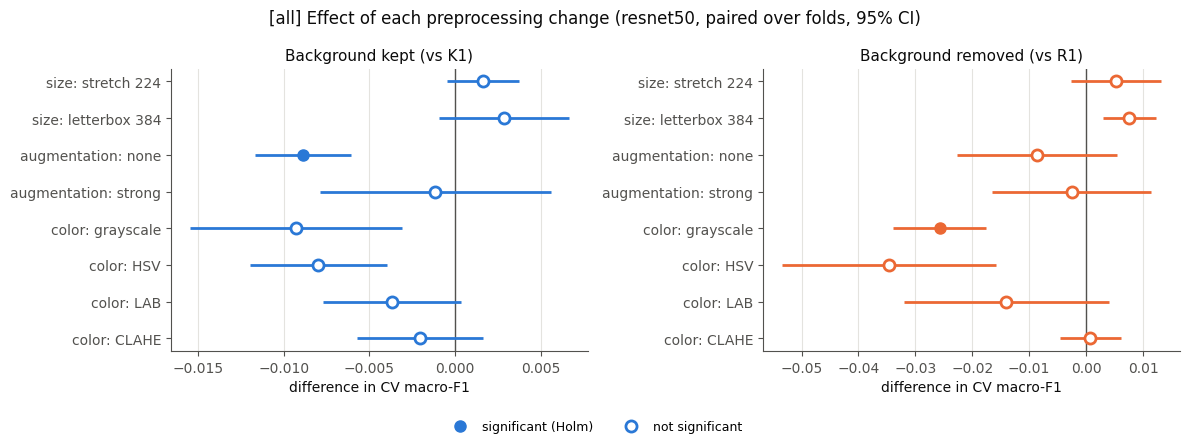

,model,pair,setting,kept,removed,diff,ci_low,ci_high,kept_better_folds,p,p_holm
0,resnet50,K1 vs R1,reference,0.9948,0.9543,0.0405,0.0340,0.0469,5/5,0.0001,0.0008
1,resnet50,K2 vs R2,size: stretch 224,0.9964,0.9595,0.0369,0.0306,0.0432,5/5,0.0001,0.0009
2,resnet50,K3 vs R3,size: letterbox 384,0.9976,0.9619,0.0357,0.0285,0.0430,5/5,0.0002,0.0017
3,resnet50,K4 vs R4,augmentation: none,0.9859,0.9457,0.0402,0.0248,0.0557,5/5,0.0019,0.0058
4,resnet50,K5 vs R5,augmentation: strong,0.9936,0.9518,0.0419,0.0258,0.0579,5/5,0.0019,0.0058
5,resnet50,K6 vs R6,color: grayscale,0.9855,0.9286,0.0569,0.0453,0.0685,5/5,0.0002,0.0017
6,resnet50,K7 vs R7,color: HSV,0.9868,0.9197,0.0671,0.0480,0.0861,5/5,0.0006,0.0037
7,resnet50,K8 vs R8,color: LAB,0.9911,0.9402,0.0509,0.0311,0.0707,5/5,0.0020,0.0058
8,resnet50,K9 vs R9,color: CLAHE,0.9927,0.9551,0.0377,0.0291,0.0462,5/5,0.0003,0.0018
9,convnext_tiny,K1 vs R1,reference,0.9943,0.9611,0.0332,0.0233,0.0432,5/5,0.0008,0.0038


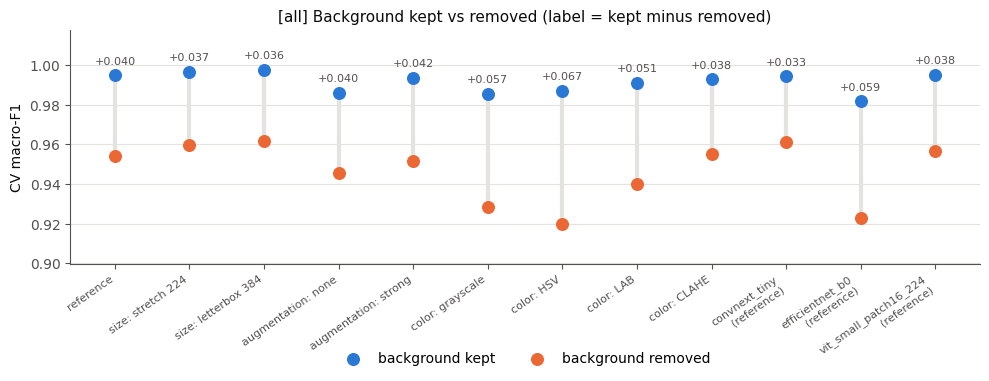

,model,cv_macro_f1,cv_std,test_macro_f1,test_f1_ci95,test_accuracy,test_balanced_acc,train_minutes,cv_diff_from_best,cv_p_vs_best,better_folds_best,mcnemar_best_only_right,mcnemar_other_only_right,mcnemar_p,cv_p_holm
0,convnext_tiny,0.9992,0.0011,0.9977,"[0.993, 1.000]",0.9976,0.9975,64.6,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,vit_small_patch16_224,0.9988,0.0018,1.0000,"[1.000, 1.000]",1.0000,1.0000,51.8,-0.0004,0.7416,2/5,0.0,1.0,1.0,0.7416
2,resnet50,0.9980,0.0013,0.9977,"[0.993, 1.000]",0.9976,0.9975,61.6,-0.0012,0.0660,4/5,0.0,0.0,1.0,0.1321
3,efficientnet_b0,0.9929,0.0029,1.0000,"[1.000, 1.000]",1.0000,1.0000,40.1,-0.0063,0.0154,5/5,0.0,1.0,1.0,0.0461


[all] best model on F: convnext_tiny


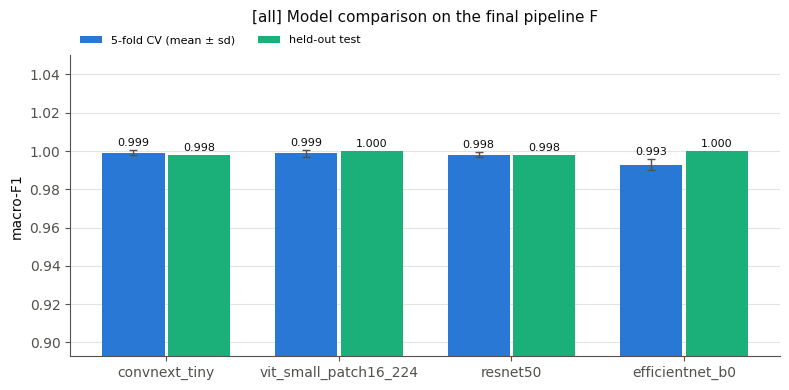

,model,Churi,Dao,Khor,Kodal,Kural,Shabol
0,convnext_tiny,1.0,0.994,1.0,0.992,1.0,1.0
1,vit_small_patch16_224,1.0,1.000,1.0,1.000,1.0,1.0
2,resnet50,1.0,0.994,1.0,0.992,1.0,1.0
3,efficientnet_b0,1.0,1.000,1.0,1.000,1.0,1.0
4,test images,68.0,79.000,62.0,67.000,63.0,80.0


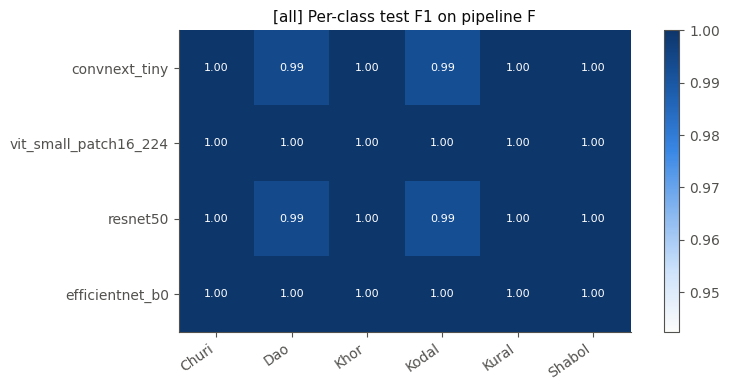

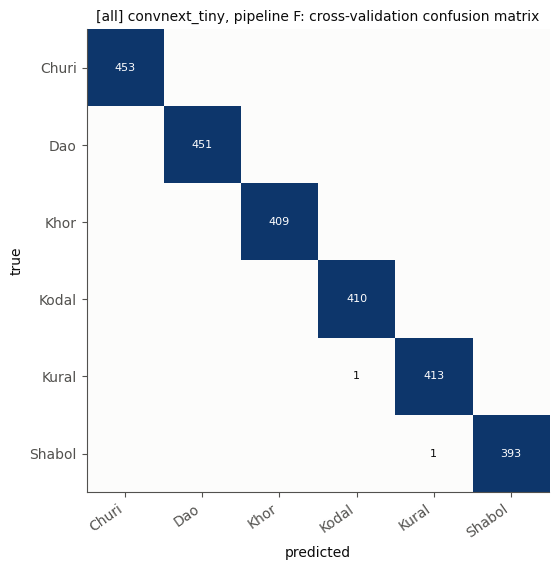

[all] most frequent confusions (true -> predicted, CV): [('Kural', 'Kodal', 1), ('Shabol', 'Kural', 1)]


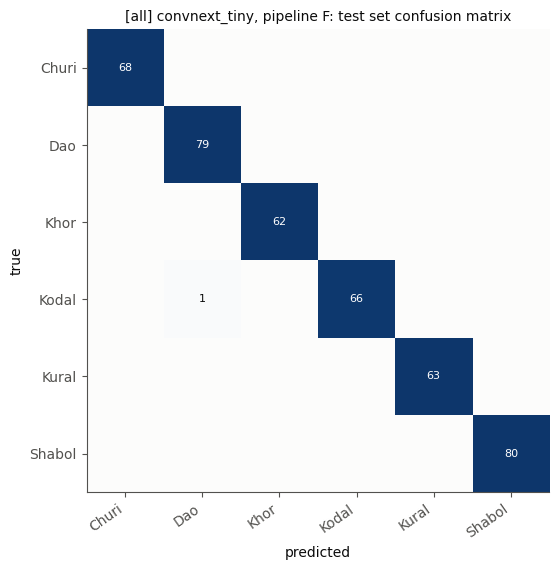

[all] attention on weapon, K1 vs R1: 0.288 vs 0.318 (Wilcoxon p = 2.1e-12, n = 406)


,model,pipeline,images,cam_on_weapon,weapon_area,focus_ratio,accuracy
0,convnext_tiny,K1,406,0.288,0.088,3.756,0.995
1,convnext_tiny,R1,406,0.318,0.088,4.467,0.978
2,convnext_tiny,F,406,0.347,0.088,4.813,0.998


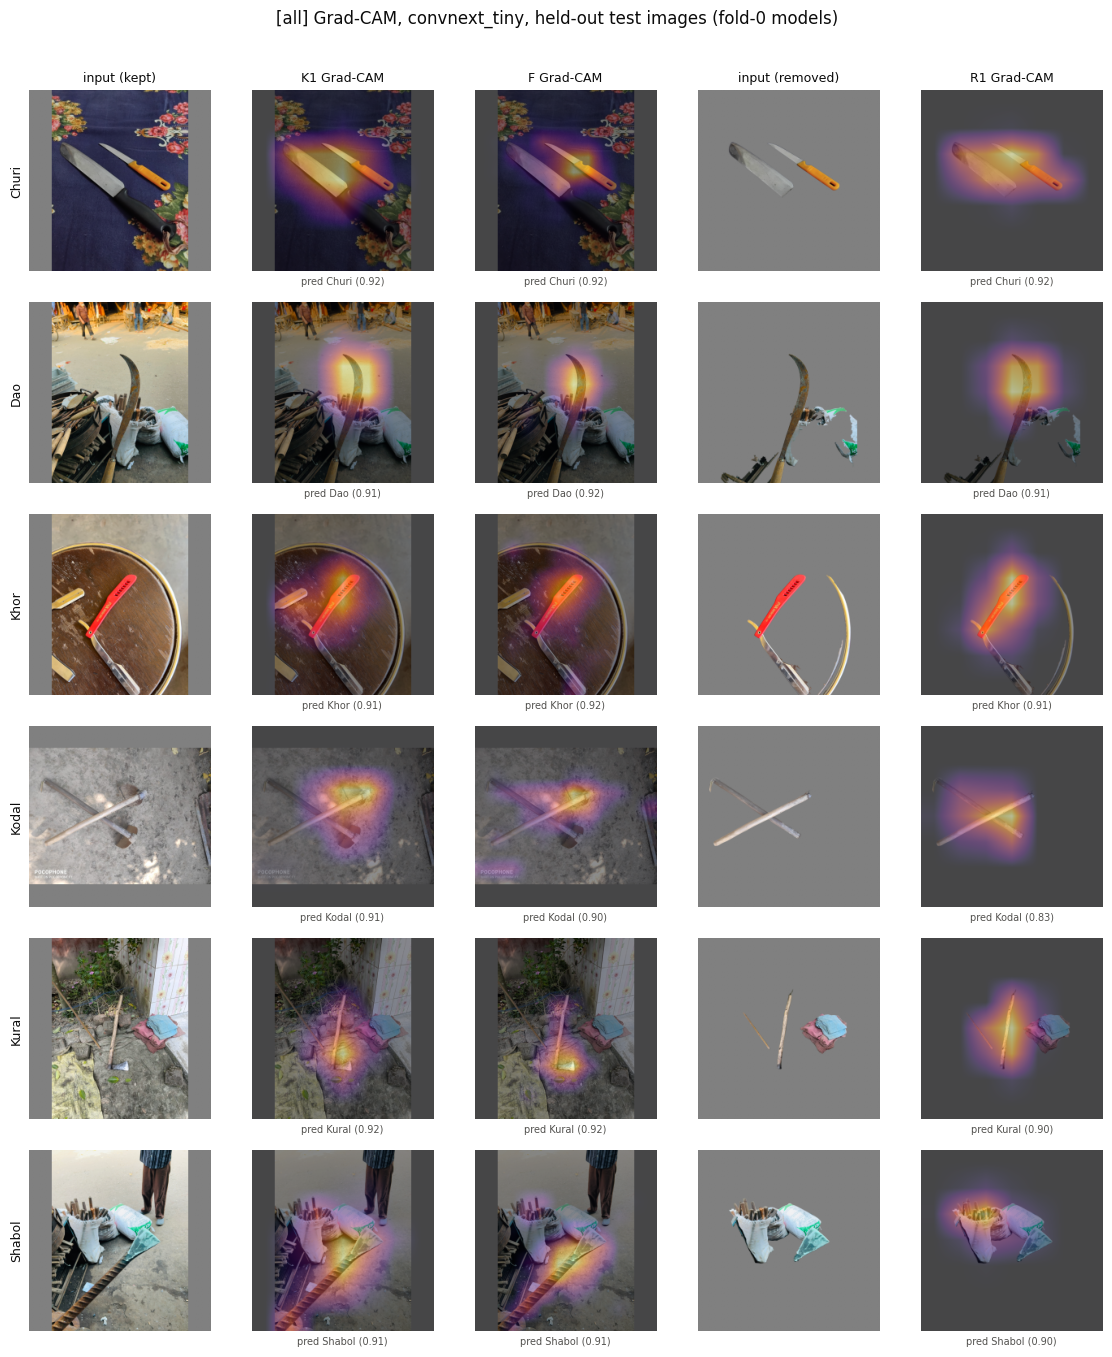


######## scenario: single ########


,pipeline,background,change,cv_macro_f1,cv_std,test_macro_f1,test_acc,diff_vs_ref,ci_low,ci_high,better_folds,p,p_holm,significant
0,K1,kept,reference,0.9960,0.0073,0.9916,0.9922,NaN,NaN,NaN,NaN,NaN,NaN,
1,K2,kept,size: stretch 224,0.9953,0.0070,0.9915,0.9922,-0.0007,-0.0026,0.0012,0/5,0.3644,1.0000,
2,K3,kept,size: letterbox 384,0.9960,0.0090,0.9829,0.9843,-0.0000,-0.0029,0.0028,1/5,0.9767,1.0000,
3,K4,kept,augmentation: none,0.9899,0.0118,0.9871,0.9882,-0.0061,-0.0125,0.0003,0/5,0.0562,0.4495,
4,K5,kept,augmentation: strong,0.9960,0.0054,0.9872,0.9882,0.0001,-0.0031,0.0032,1/5,0.9666,1.0000,
5,K6,kept,color: grayscale,0.9841,0.0076,0.9786,0.9804,-0.0119,-0.0161,-0.0077,0/5,0.0014,0.0198,yes
6,K7,kept,color: HSV,0.9876,0.0071,0.9957,0.9961,-0.0084,-0.0112,-0.0055,0/5,0.0013,0.0189,yes
7,K8,kept,color: LAB,0.9927,0.0057,0.9827,0.9843,-0.0033,-0.0060,-0.0006,0/5,0.0275,0.3021,uncorrected only
8,K9,kept,color: CLAHE,0.9924,0.0060,0.9827,0.9843,-0.0035,-0.0065,-0.0006,0/5,0.0282,0.3021,uncorrected only
9,R1,removed,reference,0.9505,0.0079,0.9640,0.9647,NaN,NaN,NaN,NaN,NaN,NaN,


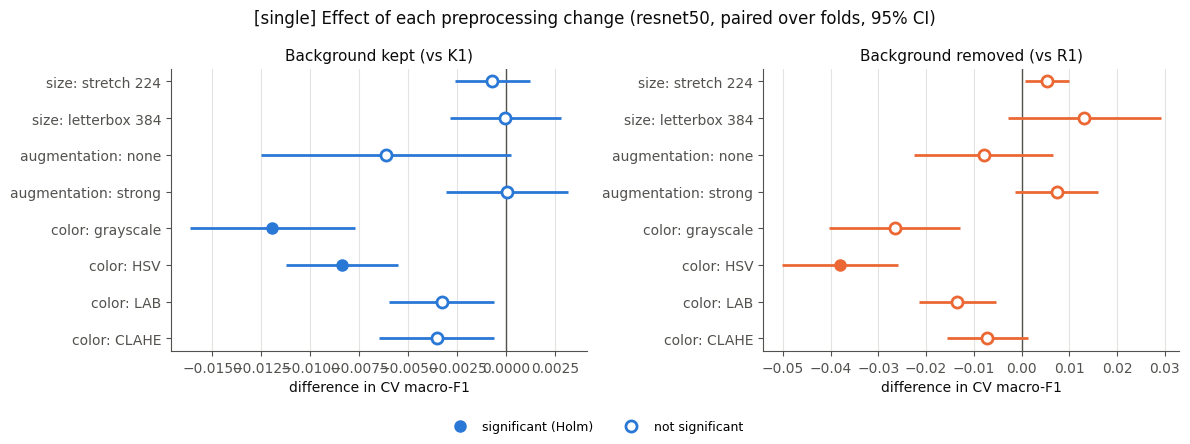

,model,pair,setting,kept,removed,diff,ci_low,ci_high,kept_better_folds,p,p_holm
0,resnet50,K1 vs R1,reference,0.9960,0.9505,0.0455,0.0354,0.0556,5/5,0.0002,0.0023
1,resnet50,K2 vs R2,size: stretch 224,0.9953,0.9558,0.0395,0.0324,0.0466,5/5,0.0001,0.0011
2,resnet50,K3 vs R3,size: letterbox 384,0.9960,0.9636,0.0324,0.0144,0.0503,5/5,0.0075,0.0123
3,resnet50,K4 vs R4,augmentation: none,0.9899,0.9425,0.0473,0.0225,0.0722,5/5,0.0062,0.0123
4,resnet50,K5 vs R5,augmentation: strong,0.9960,0.9579,0.0381,0.0295,0.0468,5/5,0.0003,0.0023
5,resnet50,K6 vs R6,color: grayscale,0.9841,0.9239,0.0601,0.0499,0.0703,5/5,0.0001,0.0010
6,resnet50,K7 vs R7,color: HSV,0.9876,0.9125,0.0752,0.0574,0.0929,5/5,0.0003,0.0023
7,resnet50,K8 vs R8,color: LAB,0.9927,0.9370,0.0557,0.0384,0.0730,5/5,0.0009,0.0044
8,resnet50,K9 vs R9,color: CLAHE,0.9924,0.9433,0.0491,0.0383,0.0600,5/5,0.0002,0.0023
9,convnext_tiny,K1 vs R1,reference,0.9993,0.9664,0.0329,0.0249,0.0409,5/5,0.0003,0.0023


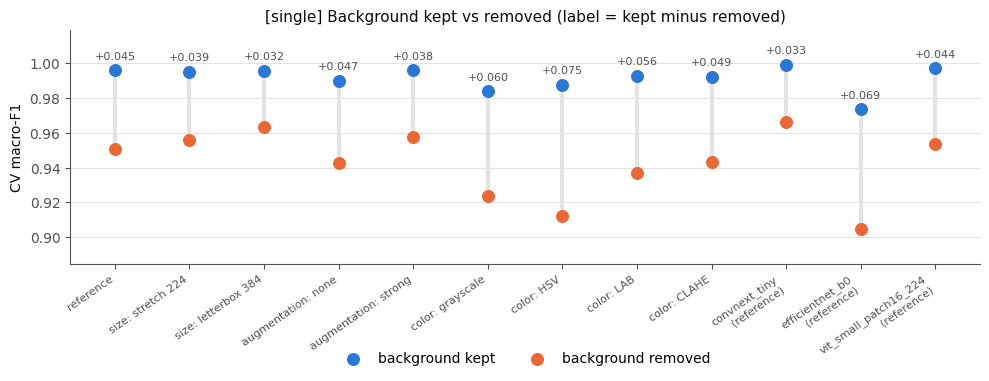

,model,cv_macro_f1,cv_std,test_macro_f1,test_f1_ci95,test_accuracy,test_balanced_acc,train_minutes,cv_diff_from_best,cv_p_vs_best,better_folds_best,mcnemar_best_only_right,mcnemar_other_only_right,mcnemar_p,cv_p_holm
0,convnext_tiny,0.9986,0.0031,0.9957,"[0.985, 1.000]",0.9961,0.9955,45.6,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,resnet50,0.9974,0.0058,0.9872,"[0.970, 1.000]",0.9882,0.9872,38.5,-0.0012,0.3739,1/5,2.0,0.0,0.5,0.7478
2,vit_small_patch16_224,0.9973,0.0059,0.9957,"[0.985, 1.000]",0.9961,0.9955,36.6,-0.0012,0.3739,1/5,0.0,0.0,1.0,0.7478
3,efficientnet_b0,0.9927,0.0098,1.0000,"[1.000, 1.000]",1.0000,1.0000,28.0,-0.0059,0.1368,3/5,0.0,1.0,1.0,0.4105


[single] best model on F: convnext_tiny


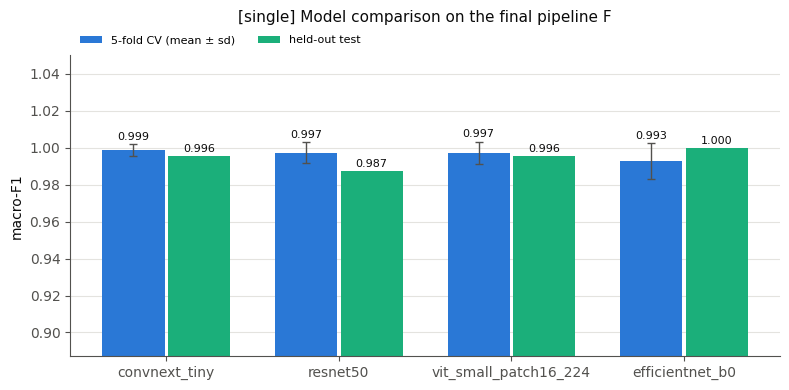

,model,Churi,Dao,Khor,Kodal,Kural,Shabol
0,convnext_tiny,0.986,1.000,1.0,0.988,1.000,1.0
1,resnet50,0.986,0.989,1.0,0.962,0.986,1.0
2,vit_small_patch16_224,0.986,1.000,1.0,0.988,1.000,1.0
3,efficientnet_b0,1.000,1.000,1.0,1.000,1.000,1.0
4,test images,37.000,43.000,50.0,40.000,36.000,49.0


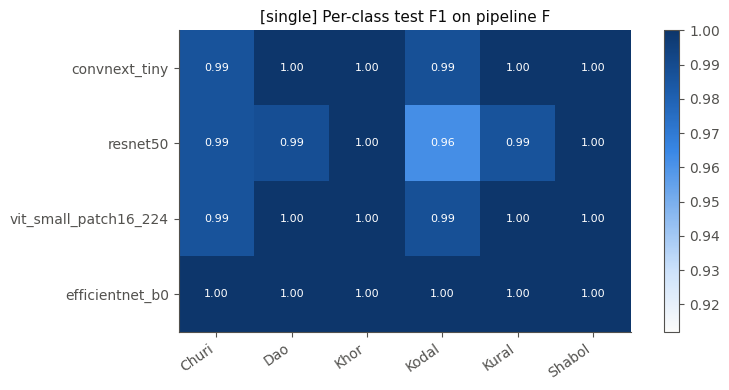

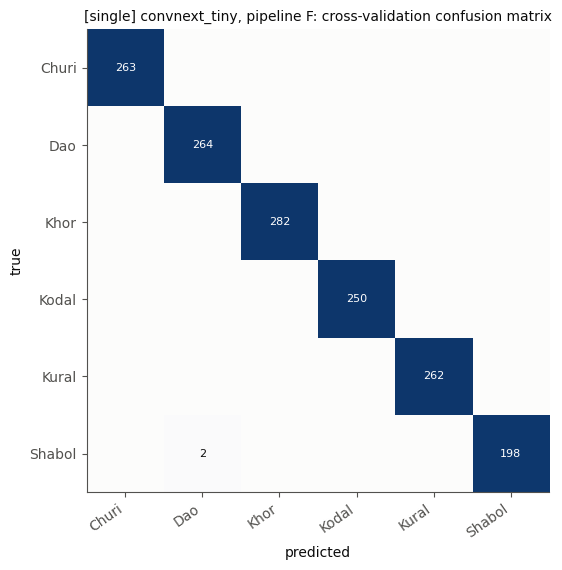

[single] most frequent confusions (true -> predicted, CV): [('Shabol', 'Dao', 2)]


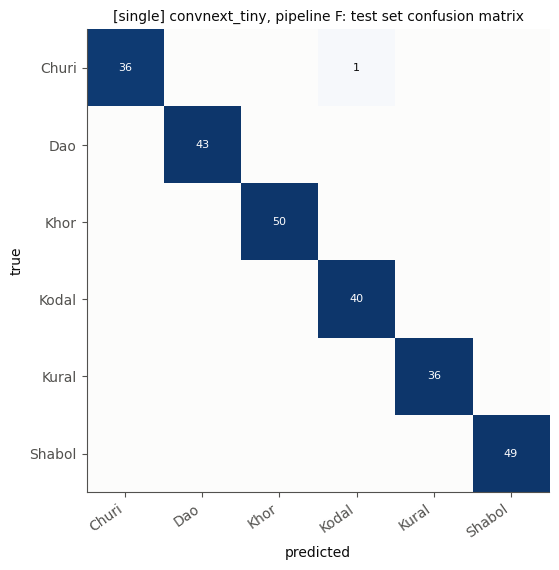

[single] attention on weapon, K1 vs R1: 0.250 vs 0.283 (Wilcoxon p = 6.4e-08, n = 250)


,model,pipeline,images,cam_on_weapon,weapon_area,focus_ratio,accuracy
0,convnext_tiny,K1,250,0.250,0.074,4.350,1.000
1,convnext_tiny,R1,250,0.283,0.074,4.964,0.976
2,convnext_tiny,F,250,0.293,0.074,5.190,0.996


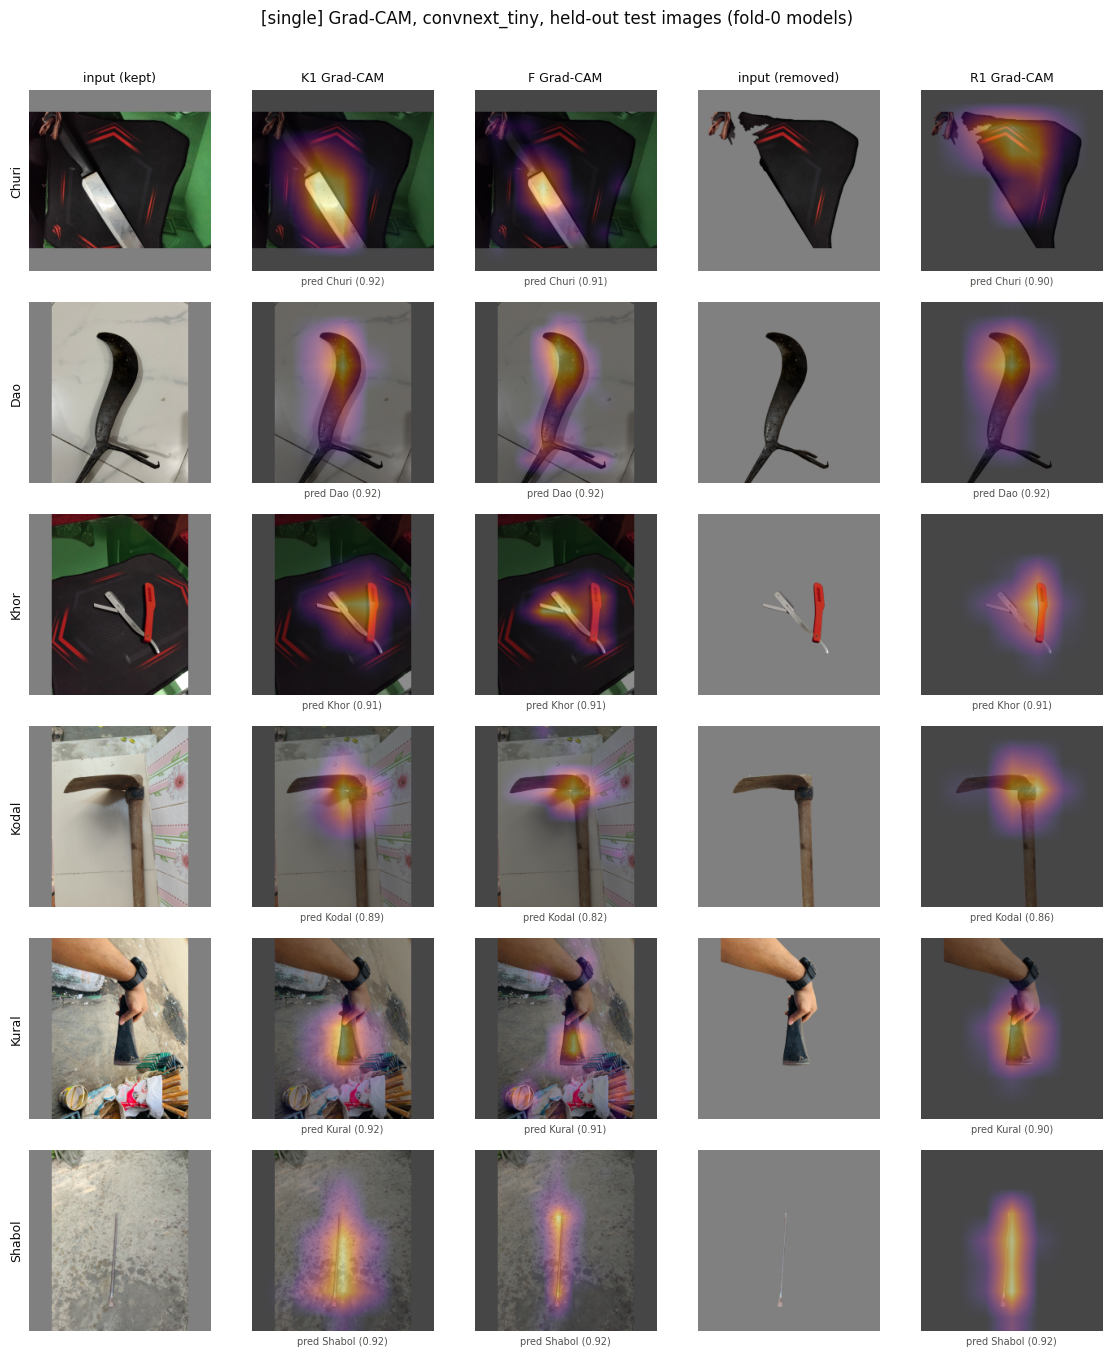


######## scenario: multi ########


,pipeline,background,change,cv_macro_f1,cv_std,test_macro_f1,test_acc,diff_vs_ref,ci_low,ci_high,better_folds,p,p_holm,significant
0,K1,kept,reference,0.9963,0.0021,0.9888,0.9878,NaN,NaN,NaN,NaN,NaN,NaN,
1,K2,kept,size: stretch 224,0.9952,0.0049,0.9950,0.9939,-0.0010,-0.0059,0.0038,1/5,0.5874,1.0000,
2,K3,kept,size: letterbox 384,0.9932,0.0045,1.0000,1.0000,-0.0031,-0.0098,0.0036,1/5,0.2715,1.0000,
3,K4,kept,augmentation: none,0.9910,0.0089,0.9893,0.9878,-0.0052,-0.0147,0.0042,1/5,0.1996,1.0000,
4,K5,kept,augmentation: strong,0.9943,0.0027,1.0000,1.0000,-0.0020,-0.0055,0.0016,1/5,0.1967,1.0000,
5,K6,kept,color: grayscale,0.9916,0.0064,0.9884,0.9878,-0.0046,-0.0109,0.0016,0/5,0.1096,1.0000,
6,K7,kept,color: HSV,0.9847,0.0054,0.9942,0.9939,-0.0116,-0.0187,-0.0044,0/5,0.0110,0.1761,uncorrected only
7,K8,kept,color: LAB,0.9929,0.0086,0.9942,0.9939,-0.0033,-0.0144,0.0077,2/5,0.4502,1.0000,
8,K9,kept,color: CLAHE,0.9941,0.0060,0.9879,0.9878,-0.0021,-0.0081,0.0038,0/5,0.3739,1.0000,
9,R1,removed,reference,0.9431,0.0118,0.9884,0.9878,NaN,NaN,NaN,NaN,NaN,NaN,


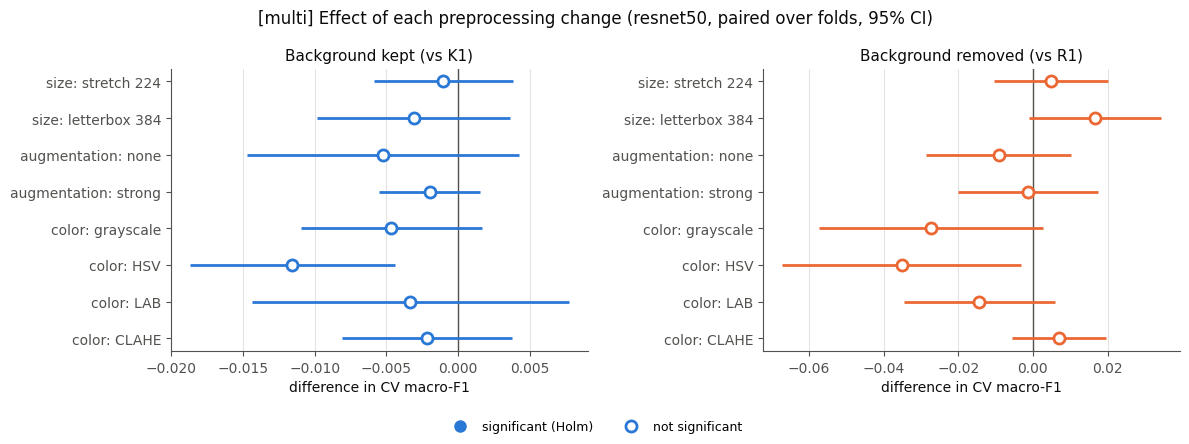

,model,pair,setting,kept,removed,diff,ci_low,ci_high,kept_better_folds,p,p_holm
0,resnet50,K1 vs R1,reference,0.9963,0.9431,0.0531,0.0408,0.0655,5/5,0.0003,0.0034
1,resnet50,K2 vs R2,size: stretch 224,0.9952,0.9480,0.0472,0.0305,0.0640,5/5,0.0014,0.0087
2,resnet50,K3 vs R3,size: letterbox 384,0.9932,0.9598,0.0334,0.0171,0.0497,5/5,0.0047,0.0194
3,resnet50,K4 vs R4,augmentation: none,0.9910,0.9339,0.0571,0.0307,0.0835,5/5,0.0039,0.0194
4,resnet50,K5 vs R5,augmentation: strong,0.9943,0.9418,0.0525,0.0348,0.0702,5/5,0.0012,0.0085
5,resnet50,K6 vs R6,color: grayscale,0.9916,0.9158,0.0758,0.0538,0.0977,5/5,0.0007,0.0060
6,resnet50,K7 vs R7,color: HSV,0.9847,0.9079,0.0768,0.0387,0.1148,5/5,0.0050,0.0194
7,resnet50,K8 vs R8,color: LAB,0.9929,0.9288,0.0641,0.0474,0.0809,5/5,0.0004,0.0049
8,resnet50,K9 vs R9,color: CLAHE,0.9941,0.9502,0.0439,0.0318,0.0560,5/5,0.0005,0.0054
9,convnext_tiny,K1 vs R1,reference,0.9990,0.9691,0.0299,0.0151,0.0448,5/5,0.0050,0.0194


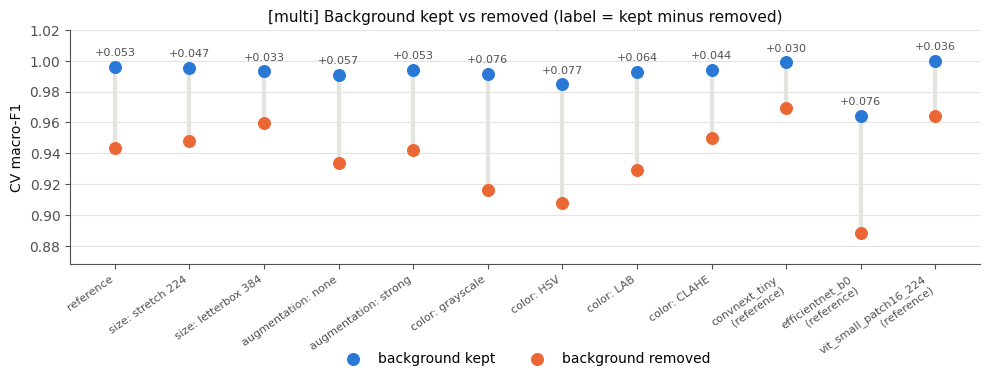

,model,cv_macro_f1,cv_std,test_macro_f1,test_f1_ci95,test_accuracy,test_balanced_acc,train_minutes,cv_diff_from_best,cv_p_vs_best,better_folds_best,mcnemar_best_only_right,mcnemar_other_only_right,mcnemar_p,cv_p_holm
0,vit_small_patch16_224,0.9980,0.0045,1.0000,"[1.000, 1.000]",1.0000,1.0000,23.7,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,convnext_tiny,0.9968,0.0048,1.0000,"[1.000, 1.000]",1.0000,1.0000,29.0,-0.0012,0.3047,2/5,0.0,0.0,1.0,0.3557
2,resnet50,0.9962,0.0042,0.9942,"[0.980, 1.000]",0.9939,0.9938,24.6,-0.0018,0.1778,2/5,1.0,0.0,1.0,0.3557
3,efficientnet_b0,0.9902,0.0048,1.0000,"[1.000, 1.000]",1.0000,1.0000,19.0,-0.0078,0.0094,5/5,0.0,0.0,1.0,0.0283


[multi] best model on F: vit_small_patch16_224


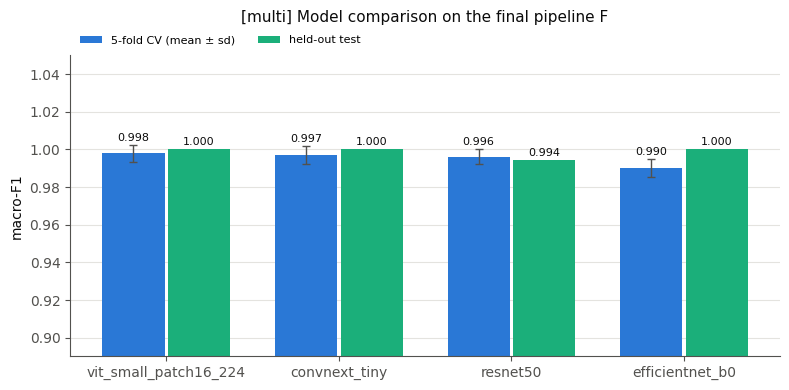

,model,Churi,Dao,Khor,Kodal,Kural,Shabol
0,vit_small_patch16_224,1.0,1.0,1.0,1.0,1.000,1.000
1,convnext_tiny,1.0,1.0,1.0,1.0,1.000,1.000
2,resnet50,1.0,1.0,1.0,1.0,0.981,0.984
3,efficientnet_b0,1.0,1.0,1.0,1.0,1.000,1.000
4,test images,31.0,36.0,12.0,27.0,27.000,31.000


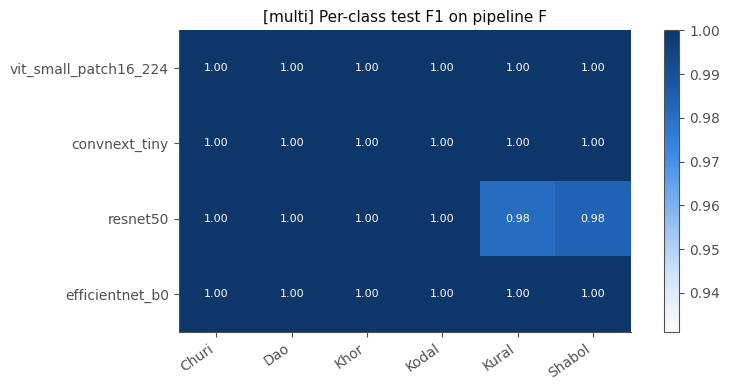

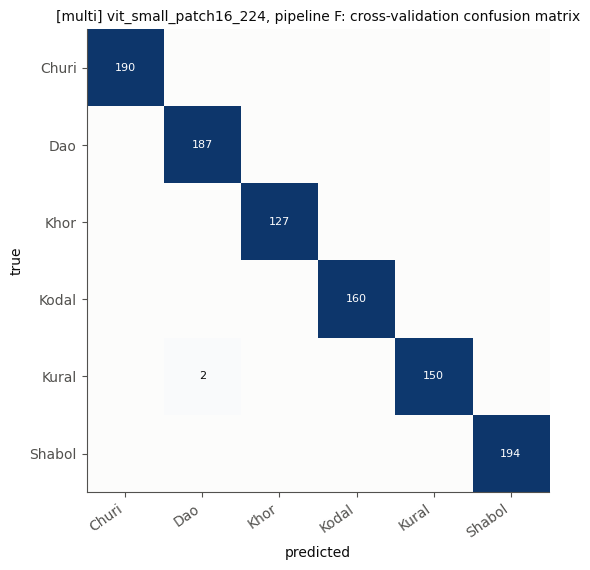

[multi] most frequent confusions (true -> predicted, CV): [('Kural', 'Dao', 2)]


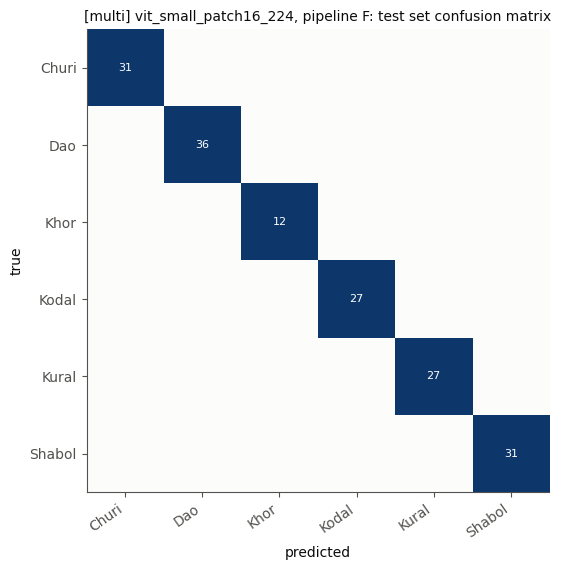

[multi] attention on weapon, K1 vs R1: 0.103 vs 0.299 (Wilcoxon p = 7.3e-26, n = 156)


,model,pipeline,images,cam_on_weapon,weapon_area,focus_ratio,accuracy
0,vit_small_patch16_224,K1,156,0.103,0.112,0.819,1.000
1,vit_small_patch16_224,R1,156,0.299,0.112,2.918,0.987
2,vit_small_patch16_224,F,156,0.057,0.112,0.428,1.000


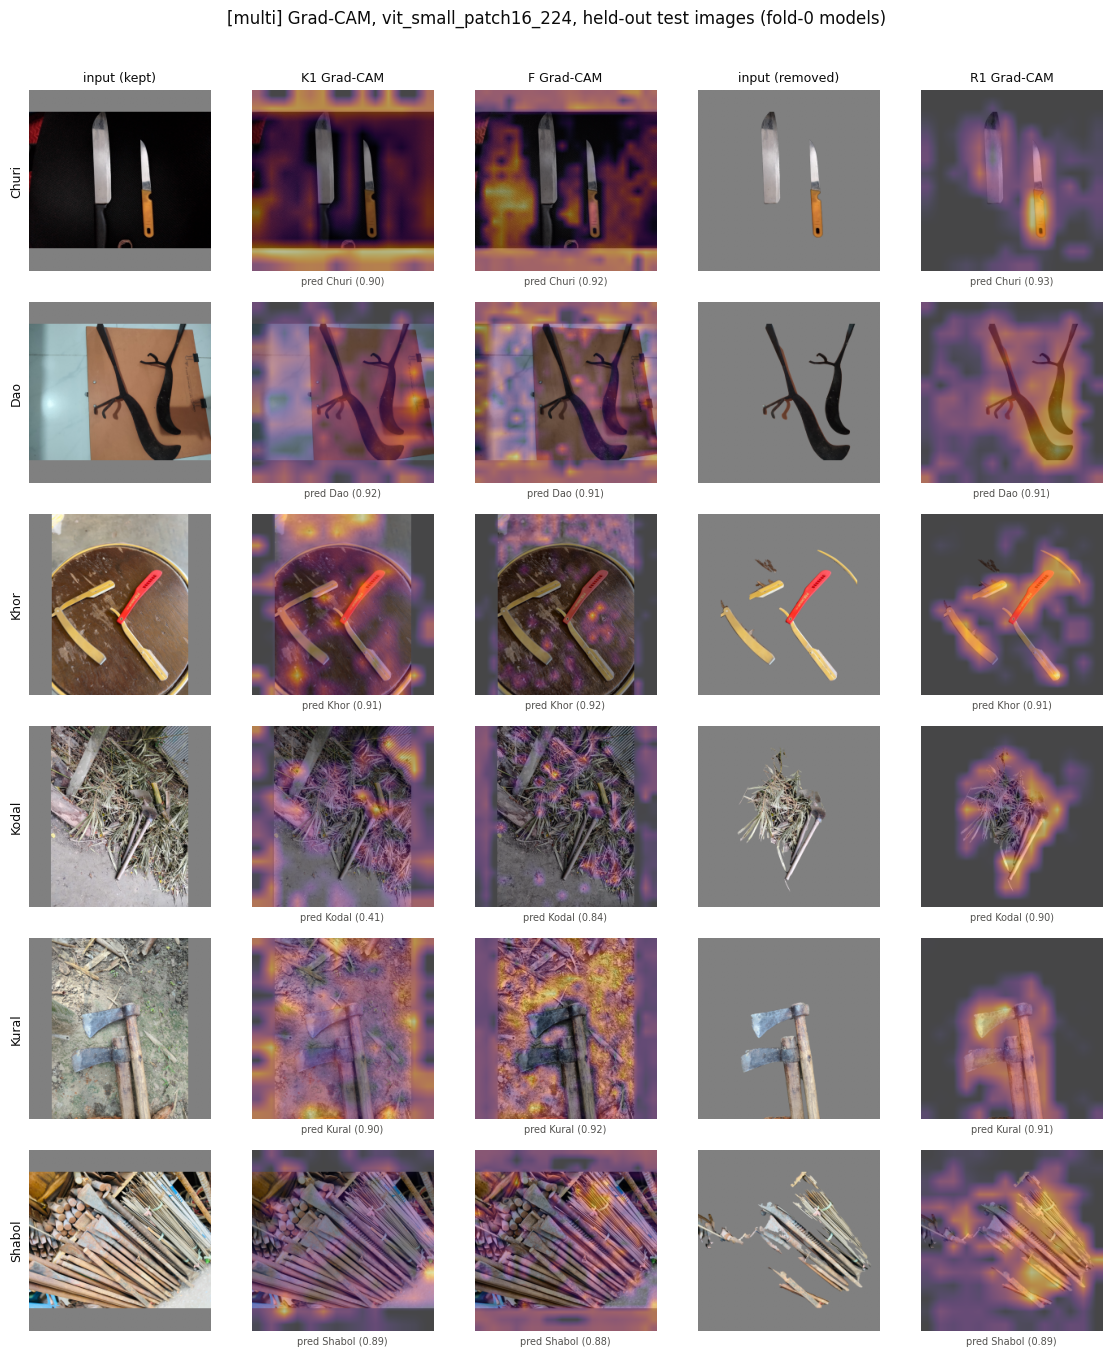

In [7]:
PER = {}
for sc in SCENARIOS:
    if sc not in RESDIRS:
        print(f"\n######## {sc}: not attached, skipped"); continue
    print(f"\n######## scenario: {sc} ########")
    tab, fig_dir = OUT / sc / "tables", OUT / sc / "figures"
    tab.mkdir(parents=True, exist_ok=True); fig_dir.mkdir(parents=True, exist_ok=True)
    t2 = ablation(sc, tab, fig_dir)
    t3 = background(sc, tab, fig_dir)
    fin, best, t4 = models_final(sc, tab, fig_dir)
    per_class(sc, fin, best, tab, fig_dir)
    t6 = gradcam(sc, best, tab, fig_dir)
    fpath = RESDIRS[sc] / "f_settings.json"
    PER[sc] = dict(t2=t2, t3=t3, fin=fin, best=best, t4=t4, t6=t6,
                   f_settings=json.loads(fpath.read_text()) if fpath.exists() else None)

### Foundation-model baseline (Table 4b)

Frozen DINOv2 ViT-S/14 features with a logistic-regression classifier (no fine-tuning), trained and tested on the same folds and test set, compared with the best fine-tuned model on F.

In [8]:
rows = []
for sc, d in PER.items():
    s = SUMMARY[sc]; lp = s[(s.model == LP_MODEL) & (s.pipeline == "LP")]
    if lp.empty or d["best"] is None:
        continue
    lp = lp.iloc[0]; b = d["fin"].iloc[0]
    p_lp, p_b = load_preds(sc, LP_MODEL, "LP"), load_preds(sc, d["best"], "F")
    lo, hi = bootstrap_f1(p_lp.y, p_lp.pred)
    j = p_lp.merge(p_b, on="image_id", suffixes=("_lp", "_best"))
    n01, n10, pm = mcnemar_exact(j.y_lp.to_numpy(), j.pred_best.to_numpy(), j.pred_lp.to_numpy())
    pr = paired(sc, d["best"], "F", LP_MODEL, "LP")
    rows.append({"scenario": sc, "baseline": "DINOv2 ViT-S/14 frozen + logistic regression",
                 "cv_macro_f1": lp.cv_macro_f1_mean, "cv_std": lp.cv_macro_f1_std, "test_macro_f1": lp.test_macro_f1,
                 "test_f1_ci95": f"[{lo:.3f}, {hi:.3f}]", "best_fine_tuned": d["best"], "best_test_macro_f1": b.test_macro_f1,
                 "cv_diff_best_minus_lp": pr["diff"] if pr else np.nan, "cv_p": pr["p"] if pr else np.nan,
                 "mcnemar_best_only_right": n01, "mcnemar_lp_only_right": n10, "mcnemar_p": pm})
T4B = pd.DataFrame(rows)
if len(T4B):
    save_table(T4B.round(4), "T4b_foundation_baseline")
else:
    print("No DINOv2 baseline found (older training output).")

,scenario,baseline,cv_macro_f1,cv_std,test_macro_f1,test_f1_ci95,best_fine_tuned,best_test_macro_f1,cv_diff_best_minus_lp,cv_p,mcnemar_best_only_right,mcnemar_lp_only_right,mcnemar_p
0,all,DINOv2 ViT-S/14 frozen + logistic regression,0.9791,0.0077,0.9847,"[0.971, 0.995]",convnext_tiny,0.9977,0.0201,0.0061,5,0,0.0625
1,single,DINOv2 ViT-S/14 frozen + logistic regression,0.9877,0.0062,0.9827,"[0.964, 0.996]",convnext_tiny,0.9957,0.0109,0.0043,3,0,0.2500
2,multi,DINOv2 ViT-S/14 frozen + logistic regression,0.9890,0.0070,0.9879,"[0.968, 1.000]",vit_small_patch16_224,1.0000,0.0090,0.0757,2,0,0.5000


## 5. Scenario comparison and single/multi cross-test (Tables 7 and 8, Figure 7)

**Cross-test:** a model trained on single-weapon images is tested on the multi-weapon test images, and the reverse. Both test sets are the locked Stage 0 test images, so none of them was seen in training. The `all` model is shown for reference, scored separately on the single and multi test images.

,scenario,best_model,F_settings,n_trainval,n_test,cv_macro_f1,cv_std,test_macro_f1,test_accuracy
0,all,convnext_tiny,"{""bg"": ""kept"", ""size"": ""letterbox"", ""res"": 384...",2531,419,0.9992,0.0011,0.9977,0.9976
1,single,convnext_tiny,"{""bg"": ""kept"", ""size"": ""letterbox"", ""res"": 384...",1521,255,0.9986,0.0031,0.9957,0.9961
2,multi,vit_small_patch16_224,"{""bg"": ""kept"", ""size"": ""letterbox"", ""res"": 384...",1010,164,0.9980,0.0045,1.0000,1.0000


,model,trained_on,test_single_macro_f1,test_single_acc,n_single,test_multi_macro_f1,test_multi_acc,n_multi,transfer_drop
0,convnext_tiny,single,0.9957,0.9961,255,0.8308,0.8171,164,0.1648
1,convnext_tiny,multi,0.8582,0.8588,255,1.0000,1.0000,164,0.1418
2,convnext_tiny,all,0.9960,0.9961,255,1.0000,1.0000,164,NaN
3,efficientnet_b0,single,1.0000,1.0000,255,0.6423,0.6280,164,0.3577
4,efficientnet_b0,multi,0.5817,0.5882,255,1.0000,1.0000,164,0.4183
5,efficientnet_b0,all,1.0000,1.0000,255,1.0000,1.0000,164,NaN
6,resnet50,single,0.9872,0.9882,255,0.7680,0.7378,164,0.2192
7,resnet50,multi,0.5416,0.5647,255,0.9942,0.9939,164,0.4526
8,resnet50,all,0.9960,0.9961,255,1.0000,1.0000,164,NaN
9,vit_small_patch16_224,single,0.9957,0.9961,255,0.6690,0.6646,164,0.3267


,model,trained_on,tested_on,class,true_images,predicted_as_this_class,precision,recall,f1
0,convnext_tiny,single,multi,Churi,31,38,0.789,0.968,0.870
1,convnext_tiny,single,multi,Dao,36,28,1.000,0.778,0.875
2,convnext_tiny,single,multi,Khor,12,12,1.000,1.000,1.000
3,convnext_tiny,single,multi,Kodal,27,31,0.806,0.926,0.862
4,convnext_tiny,single,multi,Kural,27,36,0.611,0.815,0.698
5,convnext_tiny,single,multi,Shabol,31,19,0.895,0.548,0.680
6,convnext_tiny,multi,single,Churi,37,58,0.638,1.000,0.779
7,convnext_tiny,multi,single,Dao,43,44,0.977,1.000,0.989
8,convnext_tiny,multi,single,Khor,50,42,1.000,0.840,0.913
9,convnext_tiny,multi,single,Kodal,40,47,0.787,0.925,0.851


,model,test_images,n,in_condition_f1,cross_condition_f1,only_in_condition_right,only_cross_right,mcnemar_p,mcnemar_p_holm
0,convnext_tiny,single,255,0.9957,0.8582,36,1,0.0,0.0
1,convnext_tiny,multi,164,1.0000,0.8308,30,0,0.0,0.0
2,efficientnet_b0,single,255,1.0000,0.5817,105,0,0.0,0.0
3,efficientnet_b0,multi,164,1.0000,0.6423,61,0,0.0,0.0
4,resnet50,single,255,0.9872,0.5416,109,1,0.0,0.0
5,resnet50,multi,164,0.9942,0.7680,43,1,0.0,0.0
6,vit_small_patch16_224,single,255,0.9957,0.6788,83,1,0.0,0.0
7,vit_small_patch16_224,multi,164,1.0000,0.6690,55,0,0.0,0.0


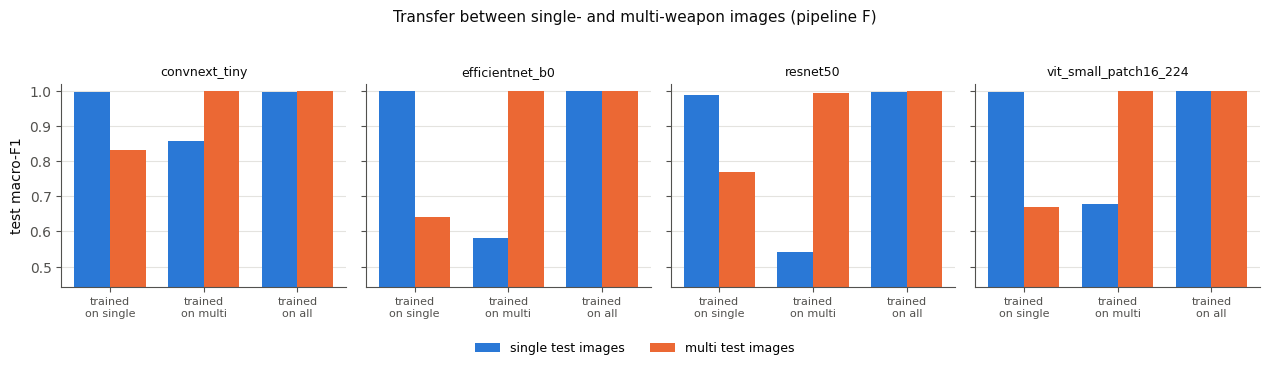

In [9]:
rows = []
for sc, d in PER.items():
    if d["best"] is None:
        continue
    b = d["fin"].iloc[0]
    rows.append({"scenario": sc, "best_model": d["best"], "F_settings": json.dumps(d["f_settings"]),
                 "n_trainval": int(b.get("n_trainval", np.nan)) if "n_trainval" in b else None,
                 "n_test": int(b.get("n_test", np.nan)) if "n_test" in b else None,
                 "cv_macro_f1": b.cv_macro_f1_mean, "cv_std": b.cv_macro_f1_std, "test_macro_f1": b.test_macro_f1,
                 "test_accuracy": b.test_accuracy})
t7 = pd.DataFrame(rows)
if len(t7):
    save_table(t7.round(4), "T7_scenarios")

def score(df):
    if df is None or not len(df):
        return np.nan, np.nan, 0
    return macro_f1(df.y, df.pred), accuracy_score(df.y, df.pred), len(df)

rows = []
models = sorted(set().union(*[set(SUMMARY[s].model[SUMMARY[s].pipeline == "F"]) for s in SUMMARY]))
for m in models:
    for sc in ("single", "multi", "all"):
        if sc not in RESDIRS or load_preds(sc, m, "F") is None:
            continue
        te = load_preds(sc, m, "F")
        if sc == "all":
            s_f1, s_acc, s_n = score(te[te.subset == "single"]); m_f1, m_acc, m_n = score(te[te.subset == "multi"])
        else:
            cr = load_preds(sc, m, "F", "cross_subset")
            own, other = (te, cr)
            (s_f1, s_acc, s_n), (m_f1, m_acc, m_n) = (score(own), score(other)) if sc == "single" else (score(other), score(own))
        rows.append({"model": m, "trained_on": sc, "test_single_macro_f1": s_f1, "test_single_acc": s_acc, "n_single": s_n,
                     "test_multi_macro_f1": m_f1, "test_multi_acc": m_acc, "n_multi": m_n})
t8 = pd.DataFrame(rows)
if len(t8):
    # within-condition minus cross-condition drop
    t8["transfer_drop"] = np.where(t8.trained_on == "single", t8.test_single_macro_f1 - t8.test_multi_macro_f1,
                                   np.where(t8.trained_on == "multi", t8.test_multi_macro_f1 - t8.test_single_macro_f1, np.nan))
    save_table(t8.round(4), "T8_cross_condition")

    # McNemar: on the same test images, the in-condition model vs the cross-condition model
    rows = []
    for m in t8.model.unique():
        for target, own_sc, other_sc in (("single", "single", "multi"), ("multi", "multi", "single")):
            if own_sc not in RESDIRS or other_sc not in RESDIRS:
                continue
            a, b = load_preds(own_sc, m, "F"), load_preds(other_sc, m, "F", "cross_subset")
            if a is None or b is None:
                continue
            j = a.merge(b, on="image_id", suffixes=("_own", "_cross"))
            n01, n10, p = mcnemar_exact(j.y_own.to_numpy(), j.pred_own.to_numpy(), j.pred_cross.to_numpy())
            rows.append({"model": m, "test_images": target, "n": len(j), "in_condition_f1": macro_f1(j.y_own, j.pred_own),
                         "cross_condition_f1": macro_f1(j.y_own, j.pred_cross), "only_in_condition_right": n01,
                         "only_cross_right": n10, "mcnemar_p": p})
    t8b = pd.DataFrame(rows)
    # per-class precision / recall / F1 of the cross-condition predictions (pipeline F)
    prf = []
    for m in t8.model.unique():
        for sc, other in (("single", "multi"), ("multi", "single")):
            if sc in RESDIRS:
                cr = load_preds(sc, m, "F", "cross_subset")
                if cr is not None:
                    prf.append(per_class_prf(cr).assign(model=m, trained_on=sc, tested_on=other))
    if prf:
        t8c = pd.concat(prf, ignore_index=True)[["model", "trained_on", "tested_on", "class", "true_images",
                                                 "predicted_as_this_class", "precision", "recall", "f1"]]
        save_table(t8c.round(3), "T8c_cross_condition_per_class_prf")
    if len(t8b):
        t8b["mcnemar_p_holm"] = holm(t8b.mcnemar_p.to_numpy())
        save_table(t8b.round(4), "T8b_cross_condition_tests")

    # Figure 7: macro-F1 on single and multi test images by training condition
    fig, axes = plt.subplots(1, len(t8.model.unique()), figsize=(3.2 * len(t8.model.unique()), 3.6), squeeze=False, sharey=True)
    for ax, m in zip(axes[0], t8.model.unique()):
        sub = t8[t8.model == m].set_index("trained_on").reindex(["single", "multi", "all"]).dropna(how="all")
        x = np.arange(len(sub)); w = 0.38
        ax.bar(x - w / 2, sub.test_single_macro_f1, w, color=BLUE, label="single test images")
        ax.bar(x + w / 2, sub.test_multi_macro_f1, w, color=ORANGE, label="multi test images")
        ax.set_xticks(x, [f"trained\non {s}" for s in sub.index], fontsize=8); ax.set_title(m, fontsize=9, color=INK)
        ax.grid(axis="x", visible=False)
    axes[0, 0].set_ylabel("test macro-F1")
    lo = np.nanmin(t8[["test_single_macro_f1", "test_multi_macro_f1"]].to_numpy())
    axes[0, 0].set_ylim(max(0, lo - 0.1), 1.02)
    h, l = axes[0, 0].get_legend_handles_labels()
    fig.legend(h, l, loc="lower center", ncol=2, frameon=False, fontsize=9)
    fig.suptitle("Transfer between single- and multi-weapon images (pipeline F)", color=INK, fontsize=11)
    fig.tight_layout(rect=[0, 0.08, 1, 0.95]); fig.savefig(FIG / "F7_cross_condition.png"); plt.show()

## 6. Device bias (Tables 9 and 10, Figure 8)

Class and capture device are associated in this dataset (Stage 0 reports Cramér's V for class vs device). Two checks show whether the model relies on the device:

1. **Minority-device check** (best model on F, scenario `all`): within each class, accuracy on images from the class's most common phone vs its other phones. Every image is scored by a model that never trained on it: out-of-fold predictions for train/val images plus test predictions. If accuracy holds on the minority phones, the model is not using the phone as a shortcut.
2. **Cross-device test**: the same model and settings trained on iPhone images only, scored on held-out iPhone test images (same phone) and on every image from the other phones (unseen phones). Two versions: background kept (`F_iphone`) and background removed (`F_iphone_bgremoved`). If removing the background narrows the gap, the scene around the weapon, not the weapon, is what fails to transfer. As a paired reference on the same images, the full model's test predictions on non-iPhone test images are compared with each one-phone model (McNemar).

Minority-device check: convnext_tiny on F, scenario all, 2950 images (CV + test).


,class,device,role,images,accuracy,ci_low,ci_high,errors_to,fisher_p_vs_main,fisher_p_holm
0,Churi,Galaxy M14,main,315,1.0000,0.9880,1.0000,,NaN,NaN
1,Churi,WhatsApp (no camera EXIF),minority,2,1.0000,0.3424,1.0000,,NaN,NaN
2,Churi,iPhone 14,minority,204,1.0000,0.9815,1.0000,,NaN,NaN
3,Churi,all minority phones,minority (pooled),206,1.0000,0.9817,1.0000,,1.0000,1.0
4,Dao,Redmi Note 15,minority,221,1.0000,0.9829,1.0000,,NaN,NaN
5,Dao,WhatsApp (no camera EXIF),minority,44,1.0000,0.9197,1.0000,,NaN,NaN
6,Dao,iPhone 14,main,265,1.0000,0.9857,1.0000,,NaN,NaN
7,Dao,all minority phones,minority (pooled),265,1.0000,0.9857,1.0000,,1.0000,1.0
8,Khor,Galaxy M14,minority,223,1.0000,0.9831,1.0000,,NaN,NaN
9,Khor,iPhone 14,main,248,1.0000,0.9847,1.0000,,NaN,NaN


F_iphone (background kept): same phone 1.000 vs unseen phones 0.534 macro-F1 (drop +0.466)


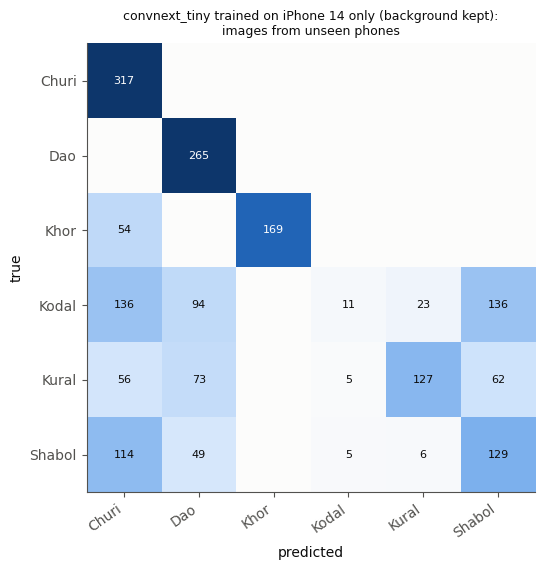

F_iphone_bgremoved (background removed): same phone 0.987 vs unseen phones 0.595 macro-F1 (drop +0.392)


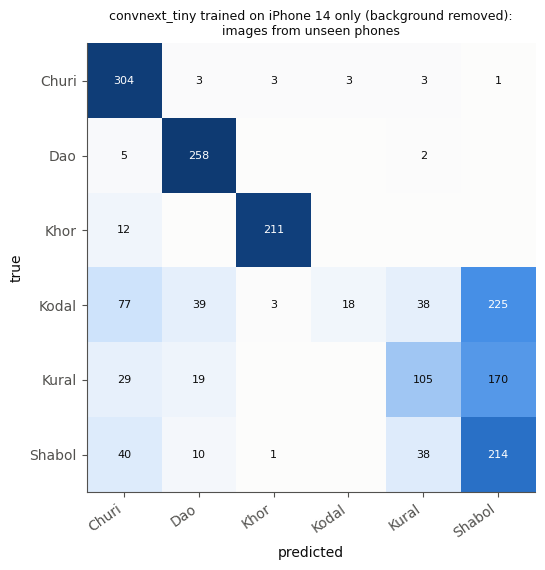

F_iphone_camaug (camera-simulation augmentation): same phone 1.000 vs unseen phones 0.507 macro-F1 (drop +0.493)


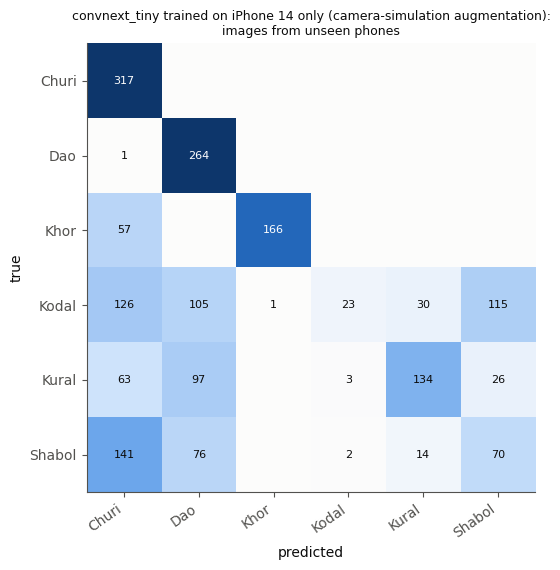

LP_iphone (DINOv2 features + logistic regression): same phone 0.989 vs unseen phones 0.613 macro-F1 (drop +0.376)


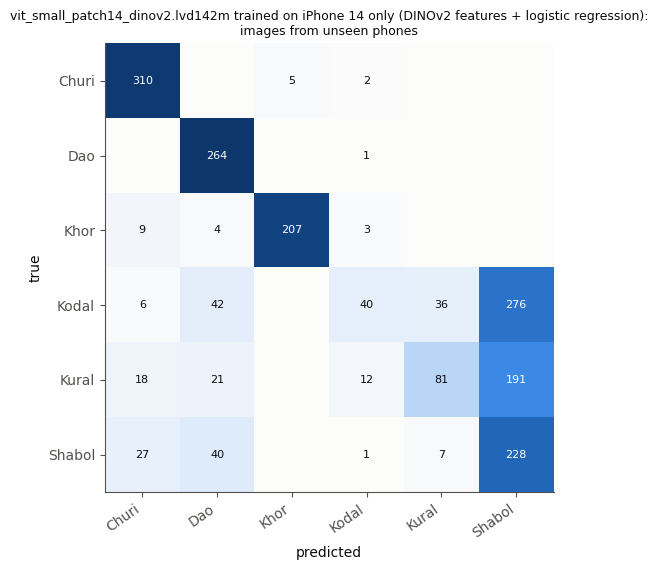

,model,training images,test images,n,macro_f1,f1_ci95,accuracy
0,F_iphone,background kept,iPhone 14 test (same phone),163,1.0000,"[1.000, 1.000]",1.0000
1,F_iphone,background kept,all other phones (unseen),1831,0.5338,"[0.513, 0.551]",0.5560
2,F_iphone,background kept,"Galaxy M14 (classes: Churi, Khor)",538,0.8916,,0.8996
3,F_iphone,background kept,"Redmi Note 15 (classes: Dao, Kodal, Kural, S...",647,0.4836,,0.5518
4,F_iphone,background kept,"WhatsApp (no camera EXIF) (classes: Churi, D...",646,0.2636,,0.2740
5,F_iphone_bgremoved,background removed,iPhone 14 test (same phone),163,0.9869,"[0.965, 1.000]",0.9877
6,F_iphone_bgremoved,background removed,all other phones (unseen),1831,0.5947,"[0.577, 0.612]",0.6062
7,F_iphone_bgremoved,background removed,"Galaxy M14 (classes: Churi, Khor)",538,0.9630,,0.9535
8,F_iphone_bgremoved,background removed,"Redmi Note 15 (classes: Dao, Kodal, Kural, S...",647,0.5076,,0.5951
9,F_iphone_bgremoved,background removed,"WhatsApp (no camera EXIF) (classes: Churi, D...",646,0.3056,,0.3282


,one_phone_model,images,n,full_model_f1 (trained on all phones),one_phone_model_f1 (never saw these phones),only_full_right,only_one_phone_right,mcnemar_p,mcnemar_p_holm
0,F_iphone,non-iPhone test images,256,0.9962,0.5459,111,0,0.0,0.0
1,F_iphone_bgremoved,non-iPhone test images,256,0.9962,0.5912,104,0,0.0,0.0
2,F_iphone_camaug,non-iPhone test images,256,0.9962,0.5023,121,0,0.0,0.0
3,LP_iphone,non-iPhone test images,256,0.9962,0.6193,98,0,0.0,0.0


Per-class precision / recall / F1 on unseen phones (predicted_as_this_class >> true_images = sink class):


,variant,approach,test_images,class,true_images,predicted_as_this_class,precision,recall,f1
0,F_iphone,background kept,unseen phones,Churi,317,677,0.468,1.000,0.638
1,F_iphone,background kept,unseen phones,Dao,265,481,0.551,1.000,0.710
2,F_iphone,background kept,unseen phones,Khor,223,169,1.000,0.758,0.862
3,F_iphone,background kept,unseen phones,Kodal,400,21,0.524,0.028,0.052
4,F_iphone,background kept,unseen phones,Kural,323,156,0.814,0.393,0.530
5,F_iphone,background kept,unseen phones,Shabol,303,327,0.394,0.426,0.410
6,F_iphone_bgremoved,background removed,unseen phones,Churi,317,467,0.651,0.959,0.776
7,F_iphone_bgremoved,background removed,unseen phones,Dao,265,329,0.784,0.974,0.869
8,F_iphone_bgremoved,background removed,unseen phones,Khor,223,218,0.968,0.946,0.957
9,F_iphone_bgremoved,background removed,unseen phones,Kodal,400,21,0.857,0.045,0.086


Per-class accuracy, same phone vs unseen phones:


,F_iphone: same phone,F_iphone: unseen phones,F_iphone_bgremoved: same phone,F_iphone_bgremoved: unseen phones,F_iphone_camaug: same phone,F_iphone_camaug: unseen phones,LP_iphone: same phone,LP_iphone: unseen phones
label,,,,,,,,
Churi,1.0,1.000,0.962,0.959,1.0,1.000,0.962,0.978
Dao,1.0,1.000,1.000,0.974,1.0,0.996,1.000,0.996
Khor,1.0,0.758,1.000,0.946,1.0,0.744,1.000,0.928
Kodal,1.0,0.028,1.000,0.045,1.0,0.058,1.000,0.100
Kural,1.0,0.393,1.000,0.325,1.0,0.415,1.000,0.251
Shabol,1.0,0.426,0.973,0.706,1.0,0.231,1.000,0.752


Unseen phones: each approach vs F_iphone (background kept, standard augmentation):


,variant,approach,n,F_iphone_f1,variant_f1,gain,only_variant_right,only_F_iphone_right,mcnemar_p,mcnemar_p_holm
0,F_iphone_bgremoved,background removed,1831,0.5338,0.5947,0.0609,184,92,0.0000,0.0000
1,F_iphone_camaug,camera-simulation augmentation,1831,0.5338,0.5068,-0.0270,36,80,0.0001,0.0001
2,LP_iphone,DINOv2 features + logistic regression,1831,0.5338,0.6130,0.0792,218,106,0.0000,0.0000


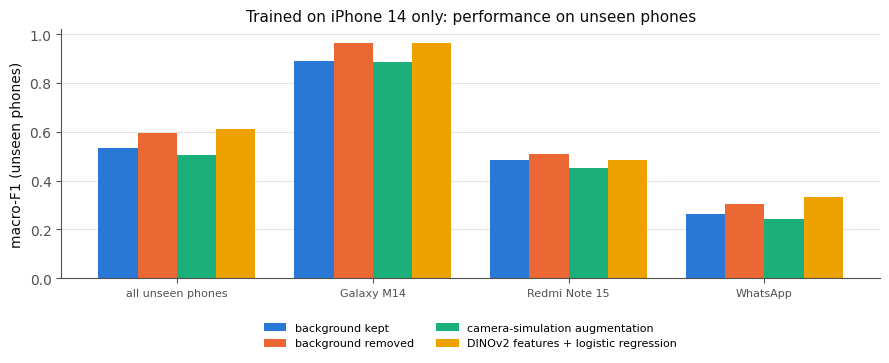

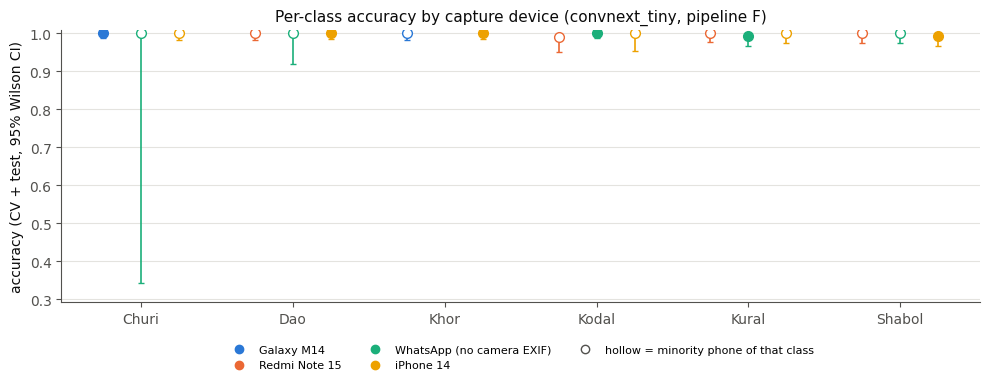

In [10]:
T9 = T10 = None
if "all" in PER and PER["all"]["best"]:
    best_all = PER["all"]["best"]
    oof, te = load_preds("all", best_all, "F", "oof"), load_preds("all", best_all, "F", "test")
    pool = pd.concat([oof.assign(source="cv"), te.assign(source="test")], ignore_index=True)
    pool["correct"] = pool.y == pool.pred
    pool["label"] = pool.y.map(dict(enumerate(CLASSES)))
    rows = []
    for c in CLASSES:
        g = pool[pool.label == c]
        main = g.device.value_counts().idxmax()
        for dev, gd in g.groupby("device"):
            k, n = int(gd.correct.sum()), len(gd)
            lo, hi = wilson(k, n)
            wrong = gd[~gd.correct].pred.map(dict(enumerate(CLASSES))).value_counts()
            rows.append({"class": c, "device": dev, "role": "main" if dev == main else "minority", "images": n,
                         "accuracy": k / n, "ci_low": lo, "ci_high": hi,
                         "errors_to": ", ".join(f"{a} {b}" for a, b in wrong.items())})
        mi = g[g.device != main]
        if len(mi):
            gm = g[g.device == main]
            tbl = [[int(gm.correct.sum()), int((~gm.correct).sum())], [int(mi.correct.sum()), int((~mi.correct).sum())]]
            k, n = int(mi.correct.sum()), len(mi); lo, hi = wilson(k, n)
            rows.append({"class": c, "device": "all minority phones", "role": "minority (pooled)", "images": n,
                         "accuracy": k / n, "ci_low": lo, "ci_high": hi,
                         "fisher_p_vs_main": stats.fisher_exact(tbl)[1], "errors_to": ""})
    T9 = pd.DataFrame(rows)
    if "fisher_p_vs_main" in T9:
        m = T9.fisher_p_vs_main.notna()
        T9.loc[m, "fisher_p_holm"] = holm(T9.loc[m, "fisher_p_vs_main"].to_numpy())
    print(f"Minority-device check: {best_all} on F, scenario all, {len(pool)} images (CV + test).")
    save_table(T9.round(4), "T9_minority_device")

    VARIANTS = {"F_iphone": (best_all, "background kept"),
                "F_iphone_bgremoved": (best_all, "background removed"),
                "F_iphone_camaug": (best_all, "camera-simulation augmentation"),
                "LP_iphone": (LP_MODEL, "DINOv2 features + logistic regression")}
    t10_rows, t10b_rows, pcs, done_v, prf_rows = [], [], [], [], []
    for vname, (vmodel, vlabel) in VARIANTS.items():
        if not (RESDIRS["all"] / vmodel / vname / "summary.json").exists():
            print(f"{vname} not found (older training output): skipped."); continue
        done_v.append(vname)
        same, cross = load_preds("all", vmodel, vname, "test"), load_preds("all", vmodel, vname, "cross_device")
        prf_rows.append(per_class_prf(cross).assign(variant=vname, approach=vlabel, test_images="unseen phones"))
        f1s, acc, n = score(same); lo, hi = bootstrap_f1(same.y, same.pred)
        t10_rows.append({"model": vname, "training images": vlabel, "test images": f"{CROSS_DEVICE_TRAIN} test (same phone)",
                         "n": n, "macro_f1": f1s, "f1_ci95": f"[{lo:.3f}, {hi:.3f}]", "accuracy": acc})
        f1c, acc, n = score(cross); lo, hi = bootstrap_f1(cross.y, cross.pred)
        t10_rows.append({"model": vname, "training images": vlabel, "test images": "all other phones (unseen)",
                         "n": n, "macro_f1": f1c, "f1_ci95": f"[{lo:.3f}, {hi:.3f}]", "accuracy": acc})
        for dev, g in cross.groupby("device"):
            present = sorted(CLASSES[i] for i in g.y.unique())
            t10_rows.append({"model": vname, "training images": vlabel,
                             "test images": f"  {dev} (classes: {', '.join(present)})", "n": len(g),
                             "macro_f1": f1_score(g.y, g.pred, average="macro", labels=sorted(g.y.unique()), zero_division=0),
                             "f1_ci95": "", "accuracy": (g.y == g.pred).mean()})
        print(f"{vname} ({vlabel}): same phone {f1s:.3f} vs unseen phones {f1c:.3f} macro-F1 (drop {f1s - f1c:+.3f})")

        # paired check on identical images: non-iPhone TEST images, full model (all phones) vs this one-phone model
        j = te[te.device != CROSS_DEVICE_TRAIN].merge(cross, on="image_id", suffixes=("_full", "_iph"))
        n01, n10, p = mcnemar_exact(j.y_full.to_numpy(), j.pred_full.to_numpy(), j.pred_iph.to_numpy())
        t10b_rows.append({"one_phone_model": vname, "images": "non-iPhone test images", "n": len(j),
                          "full_model_f1 (trained on all phones)": macro_f1(j.y_full, j.pred_full),
                          "one_phone_model_f1 (never saw these phones)": macro_f1(j.y_full, j.pred_iph),
                          "only_full_right": n01, "only_one_phone_right": n10, "mcnemar_p": p})

        rc = cross.assign(correct=cross.y == cross.pred, label=cross.y.map(dict(enumerate(CLASSES))))
        rs = same.assign(correct=same.y == same.pred, label=same.y.map(dict(enumerate(CLASSES))))
        pcs.append(pd.concat([rs.groupby("label").correct.mean().rename(f"{vname}: same phone"),
                              rc.groupby("label").correct.mean().rename(f"{vname}: unseen phones")], axis=1))

        # where do the unseen-phone errors go?
        cm = confusion_matrix(cross.y, cross.pred, labels=range(NC)); cmn = cm / cm.sum(1, keepdims=True).clip(min=1)
        fig, ax = plt.subplots(figsize=(6.8, 5.8))
        ax.imshow(cmn, cmap=SEQ, vmin=0, vmax=1)
        for i in range(NC):
            for k in range(NC):
                if cm[i, k]:
                    ax.text(k, i, cm[i, k], ha="center", va="center", fontsize=8, color="white" if cmn[i, k] > 0.55 else INK)
        ax.set_xticks(range(NC), CLASSES, rotation=35, ha="right"); ax.set_yticks(range(NC), CLASSES)
        ax.set_xlabel("predicted"); ax.set_ylabel("true"); ax.grid(False)
        ax.set_title(f"{vmodel} trained on {CROSS_DEVICE_TRAIN} only ({vlabel}):\nimages from unseen phones", color=INK, fontsize=9)
        fig.tight_layout(); fig.savefig(FIG / f"F8b_cross_device_confusion_{vname}.png"); plt.show()
    if t10_rows:
        T10 = pd.DataFrame(t10_rows)
        save_table(T10.round(4), "T10_cross_device")
        t10b = pd.DataFrame(t10b_rows)
        t10b["mcnemar_p_holm"] = holm(t10b.mcnemar_p.to_numpy())
        save_table(t10b.round(4), "T10b_cross_device_paired")
        pc = pd.concat(pcs, axis=1).reindex(CLASSES)
        pc.round(3).reset_index().rename(columns={"label": "class"}).to_csv(TAB / "T10c_cross_device_per_class.csv", index=False)
        t10e = pd.concat(prf_rows, ignore_index=True)[["variant", "approach", "test_images", "class", "true_images",
                                                      "predicted_as_this_class", "precision", "recall", "f1"]]
        print("Per-class precision / recall / F1 on unseen phones (predicted_as_this_class >> true_images = sink class):")
        save_table(t10e.round(3), "T10e_cross_device_per_class_prf")
        print("Per-class accuracy, same phone vs unseen phones:"); display(pc.round(3))
        # each variant vs the baseline F_iphone on the same unseen-phone images (exact McNemar, Holm-corrected)
        if "F_iphone" in done_v:
            base = load_preds("all", best_all, "F_iphone", "cross_device")
            rows = []
            for vname in done_v:
                if vname == "F_iphone":
                    continue
                vmodel, vlabel = VARIANTS[vname]
                j = base.merge(load_preds("all", vmodel, vname, "cross_device"), on="image_id", suffixes=("_base", "_v"))
                n01, n10, p = mcnemar_exact(j.y_base.to_numpy(), j.pred_v.to_numpy(), j.pred_base.to_numpy())
                rows.append({"variant": vname, "approach": vlabel, "n": len(j),
                             "F_iphone_f1": macro_f1(j.y_base, j.pred_base), "variant_f1": macro_f1(j.y_base, j.pred_v),
                             "gain": macro_f1(j.y_base, j.pred_v) - macro_f1(j.y_base, j.pred_base),
                             "only_variant_right": n01, "only_F_iphone_right": n10, "mcnemar_p": p})
            if rows:
                t10d = pd.DataFrame(rows); t10d["mcnemar_p_holm"] = holm(t10d.mcnemar_p.to_numpy())
                print("Unseen phones: each approach vs F_iphone (background kept, standard augmentation):")
                save_table(t10d.round(4), "T10d_cross_device_mitigation")

            # Figure 8c: unseen-phone macro-F1 per approach and phone
            g = T10[T10["test images"].str.startswith("  ")].copy()
            g["phone"] = g["test images"].str.strip().str.split(" (", n=1, regex=False).str[0]
            piv = g.pivot_table(index="training images", columns="phone", values="macro_f1").reindex([VARIANTS[v][1] for v in done_v])
            allp = T10[T10["test images"] == "all other phones (unseen)"].set_index("training images").macro_f1
            piv.insert(0, "all unseen phones", allp.reindex(piv.index))
            fig, ax = plt.subplots(figsize=(9, 3.8))
            x = np.arange(len(piv.columns)); w = 0.8 / len(piv)
            for i, (lab, r) in enumerate(piv.iterrows()):
                ax.bar(x + (i - (len(piv) - 1) / 2) * w, r.to_numpy(float), w, color=CAT[i % len(CAT)], label=lab)
            ax.set_xticks(x, piv.columns, fontsize=8); ax.set_ylabel("macro-F1 (unseen phones)"); ax.set_ylim(0, 1.02)
            ax.grid(axis="x", visible=False); ax.legend(frameon=False, fontsize=8, loc="upper center", bbox_to_anchor=(0.5, -0.14), ncol=2)
            ax.set_title(f"Trained on {CROSS_DEVICE_TRAIN} only: performance on unseen phones", color=INK, fontsize=11)
            fig.tight_layout(); fig.savefig(FIG / "F8c_cross_device_mitigation.png"); plt.show()
    else:
        print("Cross-device runs not found: commit the 'all' scenario until ALL DONE.")

    # Figure 8: per-class accuracy by device (minority-device check)
    d = T9[T9.role != "minority (pooled)"]
    devs = sorted(d.device.unique()); col = {dv: CAT[i % len(CAT)] for i, dv in enumerate(devs)}
    fig, ax = plt.subplots(figsize=(10, 4))
    for i, c in enumerate(CLASSES):
        g = d[d["class"] == c].reset_index(drop=True)
        off = np.linspace(-0.25, 0.25, len(g)) if len(g) > 1 else [0]
        for o, r in zip(off, g.itertuples()):
            ax.errorbar(i + o, r.accuracy, yerr=[[max(0.0, r.accuracy - r.ci_low)], [max(0.0, r.ci_high - r.accuracy)]], fmt="o",
                        color=col[r.device], mfc=col[r.device] if r.role == "main" else "white", ms=7, capsize=2, lw=1.2)
    for dv in devs:
        ax.plot([], [], "o", color=col[dv], label=dv)
    ax.plot([], [], "o", mfc="white", color=INK2, label="hollow = minority phone of that class")
    ax.set_xticks(range(NC), CLASSES); ax.set_ylabel("accuracy (CV + test, 95% Wilson CI)")
    ax.set_ylim(max(0, d.ci_low.min() - 0.05), 1.01); ax.grid(axis="x", visible=False)
    ax.legend(frameon=False, fontsize=8, loc="upper center", bbox_to_anchor=(0.5, -0.12), ncol=3)
    ax.set_title(f"Per-class accuracy by capture device ({best_all}, pipeline F)", color=INK, fontsize=11)
    fig.tight_layout(); fig.savefig(FIG / "F8_device.png"); plt.show()
else:
    print("Scenario 'all' not available: device analysis skipped.")

## 7. Robustness to image degradation (Table 11, Figure 9)

The trained models on F (scenario `all`) are scored on the locked test images after deliberate degradation, at 5 severity levels each. The degradation is applied to the model input (after background choice and resizing), and nothing is retrained. `ROBUST_FOLDS = [0]` uses the fold-0 model of each architecture; its clean score is the reference for the relative robustness.

| Degradation | Severity 1 to 5 |
|---|---|
| Gaussian blur | sigma 0.5, 1, 2, 3, 4 (pixels at 224 px, scaled with input size) |
| Darkness | brightness x 0.8, 0.6, 0.45, 0.3, 0.2 |
| JPEG compression | quality 60, 40, 25, 15, 8 |
| Gaussian noise | std 8, 16, 24, 32, 48 (of 255) |
| Partial occlusion | gray square covering 5, 10, 20, 30, 40% of the image, random position |
| Rotation | 10, 20, 30, 45, 60 degrees |

convnext_tiny: clean macro-F1 0.993 | 360 s
vit_small_patch16_224: clean macro-F1 0.998 | 315 s
resnet50: clean macro-F1 0.995 | 325 s
efficientnet_b0: clean macro-F1 0.998 | 299 s
Mean macro-F1 over the 5 severities for each degradation:


corruption,model,clean,blur,dark,jpeg,noise,occlusion,rotation,mean_corrupted,relative_robustness
0,vit_small_patch16_224,0.9977,0.9246,0.9619,0.9844,0.9708,0.9310,0.9923,0.9608,0.9631
1,resnet50,0.9951,0.8210,0.9813,0.9218,0.8985,0.9109,0.9909,0.9207,0.9252
2,convnext_tiny,0.9927,0.6753,0.9453,0.9888,0.9470,0.8647,0.9957,0.9028,0.9094
3,efficientnet_b0,0.9977,0.6168,0.9649,0.8737,0.3882,0.8881,0.9792,0.7851,0.7869


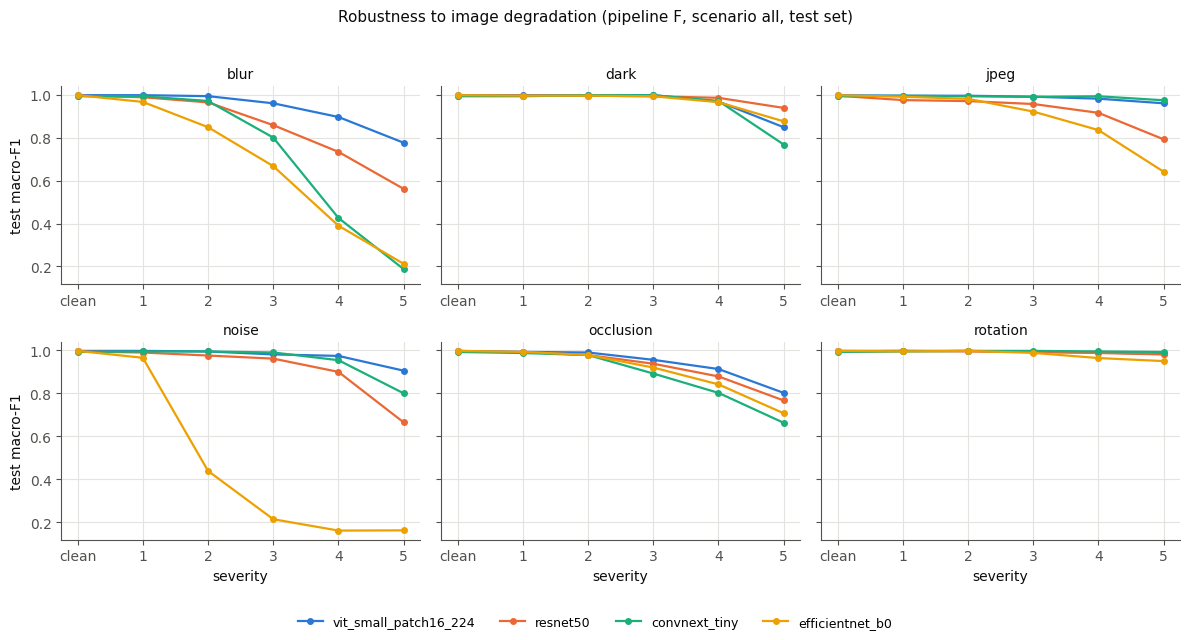

In [11]:
def corrupt(img, kind, sev, rng):
    res = img.shape[0]; scale = res / 224
    if kind == "blur":
        s = [0.5, 1, 2, 3, 4][sev - 1] * scale
        return cv2.GaussianBlur(img, (0, 0), s)
    if kind == "dark":
        return (img.astype(np.float32) * [0.8, 0.6, 0.45, 0.3, 0.2][sev - 1]).clip(0, 255).astype(np.uint8)
    if kind == "jpeg":
        ok, buf = cv2.imencode(".jpg", img[..., ::-1], [cv2.IMWRITE_JPEG_QUALITY, [60, 40, 25, 15, 8][sev - 1]])
        return cv2.imdecode(buf, cv2.IMREAD_COLOR)[..., ::-1]
    if kind == "noise":
        return (img + rng.normal(0, [8, 16, 24, 32, 48][sev - 1], img.shape)).clip(0, 255).astype(np.uint8)
    if kind == "occlusion":
        side = int(round(res * math.sqrt([0.05, 0.10, 0.20, 0.30, 0.40][sev - 1])))
        y0, x0 = rng.integers(0, res - side + 1, 2)
        out = img.copy(); out[y0:y0 + side, x0:x0 + side] = PAD_GRAY
        return out
    if kind == "rotation":
        ang = [10, 20, 30, 45, 60][sev - 1]
        M = cv2.getRotationMatrix2D((res / 2, res / 2), ang, 1.0)
        return cv2.warpAffine(img, M, (res, res), borderValue=(PAD_GRAY,) * 3)
    raise ValueError(kind)

KINDS = ["blur", "dark", "jpeg", "noise", "occlusion", "rotation"]
T11 = None
if "all" in PER and PER["all"]["best"]:
    test_all = manifest[manifest.split == "test"].reset_index(drop=True)
    y = test_all.y.to_numpy()
    rows = []
    for m in PER["all"]["fin"].model:
        folds = [k for k in ROBUST_FOLDS if has_w("all", m, "F", k)]
        if not folds:
            print(f"{m}: no F weights, skipped"); continue
        t0 = time.time()
        nets = [load_net("all", m, "F", k) for k in folds]
        cfg = nets[0][1]
        base = [load_input(r, cfg) for r in test_all.itertuples(index=False)]
        def ens(imgs):
            return np.mean([predict_arrays(n, c, imgs) for n, c in nets], axis=0)
        clean = macro_f1(y, ens(base).argmax(1))
        rows.append({"model": m, "corruption": "clean", "severity": 0, "macro_f1": clean})
        for kind in KINDS:
            for sev in SEVERITIES:
                rng = np.random.default_rng(SEED + sev)
                imgs = [corrupt(im, kind, sev, rng) for im in base]
                rows.append({"model": m, "corruption": kind, "severity": sev, "macro_f1": macro_f1(y, ens(imgs).argmax(1))})
        del nets; torch.cuda.empty_cache() if DEVICE == "cuda" else None
        print(f"{m}: clean macro-F1 {clean:.3f} | {time.time() - t0:.0f} s")
    rob = pd.DataFrame(rows)
    rob.round(4).to_csv(TAB / "T11a_robustness_all.csv", index=False)
    clean = rob[rob.corruption == "clean"].set_index("model").macro_f1
    cor = rob[rob.corruption != "clean"]
    T11 = cor.pivot_table(index="model", columns="corruption", values="macro_f1", aggfunc="mean")[KINDS]
    T11["mean_corrupted"] = cor.groupby("model").macro_f1.mean()
    T11.insert(0, "clean", clean)
    T11["relative_robustness"] = T11.mean_corrupted / T11.clean
    T11 = T11.sort_values("mean_corrupted", ascending=False)
    print("Mean macro-F1 over the 5 severities for each degradation:")
    save_table(T11.reset_index().round(4), "T11_robustness_summary")

    fig, axes = plt.subplots(2, 3, figsize=(12, 6.4), sharey=True)
    for ax, kind in zip(axes.ravel(), KINDS):
        for i, m in enumerate(T11.index):
            g = rob[(rob.model == m) & (rob.corruption.isin([kind, "clean"]))].sort_values("severity")
            ax.plot(g.severity, g.macro_f1, "-o", color=CAT[i % len(CAT)], ms=4, lw=1.6, label=m)
        ax.set_title(kind, fontsize=10, color=INK); ax.set_xticks([0] + SEVERITIES, ["clean"] + [str(s) for s in SEVERITIES])
    for ax in axes[:, 0]:
        ax.set_ylabel("test macro-F1")
    for ax in axes[-1]:
        ax.set_xlabel("severity")
    h, l = axes[0, 0].get_legend_handles_labels()
    fig.legend(h, l, loc="lower center", ncol=len(l), frameon=False, fontsize=9)
    fig.suptitle("Robustness to image degradation (pipeline F, scenario all, test set)", color=INK, fontsize=11)
    fig.tight_layout(rect=[0, 0.06, 1, 0.96]); fig.savefig(FIG / "F9_robustness.png"); plt.show()
else:
    print("Scenario 'all' not available: robustness test skipped.")

## 8. Calibration (Table 12, Figure 10)

Does a confidence of 90% mean the model is right 90% of the time? For each model on F (scenario `all`), from the saved predictions (no GPU needed):

- **ECE** (expected calibration error, 15 bins): average gap between confidence and accuracy, lower is better.
- **NLL** (negative log-likelihood) and **Brier score**: lower is better.
- **Temperature scaling**: one number `T` that rescales the probabilities, fitted on the cross-validation predictions only and then applied to the test set, so the test set stays untouched.

,model,temperature,test_ece,test_ece_scaled,test_nll,test_nll_scaled,test_brier,test_brier_scaled,mean_confidence,test_accuracy,cv_ece
0,convnext_tiny,0.3919,0.0855,0.0022,0.0954,0.0102,0.0123,0.0045,0.9129,0.9976,0.0861
1,vit_small_patch16_224,0.3588,0.0880,0.0014,0.0930,0.0017,0.0109,0.0010,0.9120,1.0000,0.0866
2,resnet50,0.3513,0.0896,0.0035,0.1019,0.0145,0.0157,0.0056,0.9086,0.9976,0.0888
3,efficientnet_b0,0.3685,0.1132,0.0032,0.1249,0.0035,0.0235,0.0008,0.8868,1.0000,0.1057


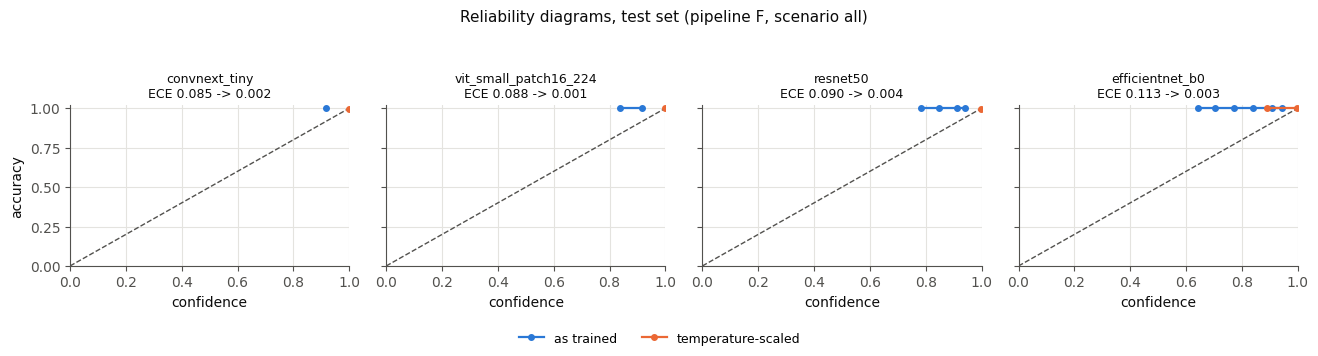

In [12]:
def ece(probs, y, bins=ECE_BINS):
    conf, pred = probs.max(1), probs.argmax(1)
    edges = np.linspace(0, 1, bins + 1); e = 0.0
    for lo, hi in zip(edges[:-1], edges[1:]):
        m = (conf > lo) & (conf <= hi)
        if m.any():
            e += m.mean() * abs((pred[m] == y[m]).mean() - conf[m].mean())
    return e

def nll(probs, y):
    return float(-np.log(probs[np.arange(len(y)), y].clip(1e-12)).mean())

def brier(probs, y):
    return float(((probs - np.eye(probs.shape[1])[y]) ** 2).sum(1).mean())

def temper(probs, T):
    z = np.log(probs.clip(1e-12)) / T
    z -= z.max(1, keepdims=True)
    e = np.exp(z)
    return e / e.sum(1, keepdims=True)

def reliability(ax, probs, y, color, label):
    conf, pred = probs.max(1), probs.argmax(1)
    edges = np.linspace(0, 1, ECE_BINS + 1); xs, ys, ns = [], [], []
    for lo, hi in zip(edges[:-1], edges[1:]):
        m = (conf > lo) & (conf <= hi)
        if m.sum() >= 3:
            xs.append(conf[m].mean()); ys.append((pred[m] == y[m]).mean()); ns.append(m.sum())
    ax.plot(xs, ys, "-o", color=color, ms=4, lw=1.6, label=label)

T12 = None
if "all" in PER and PER["all"]["best"]:
    pcols = [f"p_{c}" for c in CLASSES]
    rows, curves = [], {}
    for m in PER["all"]["fin"].model:
        oof, te = load_preds("all", m, "F", "oof"), load_preds("all", m, "F", "test")
        po, yo = oof[pcols].to_numpy(), oof.y.to_numpy()
        pt, yt = te[pcols].to_numpy(), te.y.to_numpy()
        T = optimize.minimize_scalar(lambda t: nll(temper(po, t), yo), bounds=(0.05, 10), method="bounded").x
        pt_s = temper(pt, T)
        rows.append({"model": m, "temperature": T, "test_ece": ece(pt, yt), "test_ece_scaled": ece(pt_s, yt),
                     "test_nll": nll(pt, yt), "test_nll_scaled": nll(pt_s, yt), "test_brier": brier(pt, yt),
                     "test_brier_scaled": brier(pt_s, yt), "mean_confidence": pt.max(1).mean(),
                     "test_accuracy": (pt.argmax(1) == yt).mean(), "cv_ece": ece(po, yo)})
        curves[m] = (pt, pt_s, yt)
    T12 = pd.DataFrame(rows)
    save_table(T12.round(4), "T12_calibration")

    fig, axes = plt.subplots(1, len(curves), figsize=(3.3 * len(curves), 3.5), squeeze=False, sharey=True)
    for ax, (m, (pt, pt_s, yt)) in zip(axes[0], curves.items()):
        ax.plot([0, 1], [0, 1], "--", color=INK2, lw=1)
        reliability(ax, pt, yt, BLUE, "as trained"); reliability(ax, pt_s, yt, ORANGE, "temperature-scaled")
        r = T12.set_index("model").loc[m]
        ax.set_title(f"{m}\nECE {r.test_ece:.3f} -> {r.test_ece_scaled:.3f}", fontsize=9, color=INK)
        ax.set_xlabel("confidence"); ax.set_xlim(0, 1); ax.set_ylim(0, 1.02)
    axes[0, 0].set_ylabel("accuracy")
    h, l = axes[0, 0].get_legend_handles_labels()
    fig.legend(h, l, loc="lower center", ncol=2, frameon=False, fontsize=9)
    fig.suptitle("Reliability diagrams, test set (pipeline F, scenario all)", color=INK, fontsize=11)
    fig.tight_layout(rect=[0, 0.08, 1, 0.93]); fig.savefig(FIG / "F10_reliability.png"); plt.show()

## 9. Speed and model size (Table 13)

For each architecture at the input size of pipeline F: number of parameters, computation per image (GFLOPs, counted with PyTorch's FLOP counter, 1 multiply-add = 2 FLOPs), and inference time per image. GPU times use batch size 1 and 64 (throughput); CPU times use batch size 1 with all available threads. One forward pass is timed; with test-time augmentation (flip) the cost doubles.

Timings depend on the hardware Kaggle assigns; the GPU and CPU names are printed and saved with the table.

In [13]:
from torch.utils.flop_counter import FlopCounterMode

def time_it(fn, n_warm, n_run, sync):
    for _ in range(n_warm):
        fn()
    sync(); ts = []
    for _ in range(n_run):
        t0 = time.perf_counter(); fn(); sync(); ts.append(time.perf_counter() - t0)
    return float(np.median(ts))

T13 = None
if "all" in PER and PER["all"]["best"]:
    rows = []
    gpu_name = torch.cuda.get_device_name(0) if DEVICE == "cuda" else "none"
    cpu_name = os.popen("lscpu 2>/dev/null | grep 'Model name' | head -1").read().split(":")[-1].strip() or "unknown"
    torch.set_num_threads(os.cpu_count() or 1)
    speed_models = [(m, "F") for m in PER["all"]["fin"].model]
    if not SUMMARY["all"][(SUMMARY["all"].model == LP_MODEL)].empty:
        speed_models.append((LP_MODEL, "LP"))
    for m, pipe in speed_models:
        cfg = pipe_cfg("all", m, pipe); res = cfg["res"]
        kw = dict(pretrained=False, num_classes=NC)
        if m.startswith(("vit", "deit", "swin")):
            kw["img_size"] = res
        net = timm.create_model(m, **kw).eval()   # for the linear probe the head stands in for logistic regression
        params = sum(p.numel() for p in net.parameters()) / 1e6
        x1 = torch.randn(1, 3, res, res)
        with torch.no_grad(), FlopCounterMode(display=False) as fc:
            net(x1)
        gflops = fc.get_total_flops() / 1e9
        with torch.no_grad():
            cpu_ms = time_it(lambda: net(x1), 3, 15, lambda: None) * 1000
        row = {"model": m, "input_px": res, "params_M": params, "GFLOPs": gflops, "cpu_ms_per_image": cpu_ms}
        if DEVICE == "cuda":
            g = net.cuda(); xg1 = x1.cuda(); xg64 = torch.randn(64, 3, res, res, device="cuda")
            sync = torch.cuda.synchronize
            with torch.no_grad(), torch.autocast("cuda"):
                row["gpu_ms_per_image_b1"] = time_it(lambda: g(xg1), 10, 50, sync) * 1000
                row["gpu_images_per_s_b64"] = 64 / time_it(lambda: g(xg64), 3, 10, sync)
        rows.append(row)
        del net; torch.cuda.empty_cache() if DEVICE == "cuda" else None
    T13 = pd.DataFrame(rows)
    T13["model"] = T13.model.replace({LP_MODEL: "DINOv2 ViT-S/14 + logistic regression"})
    T13["hardware"] = f"GPU: {gpu_name} | CPU: {cpu_name}, {os.cpu_count()} threads"
    save_table(T13.round(2), "T13_speed_size")

,model,input_px,params_M,GFLOPs,cpu_ms_per_image,gpu_ms_per_image_b1,gpu_images_per_s_b64,hardware
0,convnext_tiny,384,27.82,26.18,152.75,7.24,210.21,GPU: Tesla T4 | CPU: Intel(R) Xeon(R) CPU @ 2....
1,vit_small_patch16_224,384,21.81,24.84,180.97,6.10,297.75,GPU: Tesla T4 | CPU: Intel(R) Xeon(R) CPU @ 2....
2,resnet50,384,23.52,24.02,164.07,6.36,216.21,GPU: Tesla T4 | CPU: Intel(R) Xeon(R) CPU @ 2....
3,efficientnet_b0,384,4.02,2.26,55.57,8.17,542.88,GPU: Tesla T4 | CPU: Intel(R) Xeon(R) CPU @ 2....
4,DINOv2 ViT-S/14 + logistic regression,224,21.63,11.03,77.36,6.25,746.49,GPU: Tesla T4 | CPU: Intel(R) Xeon(R) CPU @ 2....


## 10. Key numbers for the results section

In [14]:
L = [f"- Dataset: {len(manifest)} images; class vs capture device Cramer's V = {cramers_v_device:.3f}."]
for sc, d in PER.items():
    L.append(f"\n## Scenario: {sc}")
    t2, t3, t4 = d["t2"], d["t3"], d["t4"]
    if len(t2) and "diff_vs_ref" in t2:
        k1 = t2[t2.pipeline == "K1"]
        if len(k1):
            k1 = k1.iloc[0]
            L.append(f"- Reference K1 ({REFERENCE_MODEL}): CV macro-F1 {k1.cv_macro_f1:.3f} ± {k1.cv_std:.3f}, test {k1.test_macro_f1:.3f}.")
        for r in t2.dropna(subset=["diff_vs_ref"]).itertuples():
            if r.p_holm < 0.05:
                L.append(f"- {r.pipeline} ({r.change}, background {r.background}): {r.diff_vs_ref:+.3f} vs reference "
                         f"(95% CI {r.ci_low:+.3f} to {r.ci_high:+.3f}; better in {r.better_folds} folds; Holm p = {r.p_holm:.3g}).")
    if len(t3):
        k = t3[t3.model == REFERENCE_MODEL]
        if len(k):
            L.append(f"- Background kept beat removed in {int((k['diff'] > 0).sum())} of {len(k)} pairs ({REFERENCE_MODEL}); "
                     f"mean difference {k['diff'].mean():+.3f}.")
    if len(t4):
        b = t4.iloc[0]
        L.append(f"- Best model on F: {b.model}, CV {b.cv_macro_f1:.3f} ± {b.cv_std:.3f}, test macro-F1 {b.test_macro_f1:.3f} "
                 f"{b.test_f1_ci95}, accuracy {b.test_accuracy:.3f}. F settings: {d['f_settings']}.")
    if d["t6"] is not None:
        for r in d["t6"].itertuples():
            L.append(f"- Grad-CAM {r.model} {r.pipeline}: {r.cam_on_weapon:.1%} of attention on the weapon "
                     f"(weapon covers {r.weapon_area:.1%} of the input, n = {r.images}).")
if 'T4B' in globals() and len(T4B):
    for r in T4B.itertuples():
        L.append(f"- [{r.scenario}] DINOv2 frozen baseline: test macro-F1 {r.test_macro_f1:.3f} {r.test_f1_ci95} vs "
                 f"{r.best_fine_tuned} {r.best_test_macro_f1:.3f} (McNemar p = {r.mcnemar_p:.3g}).")
L.append("\n## Across scenarios")
if 't8' in globals() and len(t8):
    for r in t8[t8.trained_on != "all"].itertuples():
        own, other = ("single", "multi") if r.trained_on == "single" else ("multi", "single")
        L.append(f"- {r.model} trained on {r.trained_on}: {getattr(r, f'test_{own}_macro_f1'):.3f} on {own} test images, "
                 f"{getattr(r, f'test_{other}_macro_f1'):.3f} on {other} test images (drop {r.transfer_drop:+.3f}).")
if T9 is not None:
    for _, r in T9[T9.role == "minority (pooled)"].iterrows():
        main = T9[(T9["class"] == r["class"]) & (T9.role == "main")].iloc[0]
        L.append(f"- {r['class']}: accuracy {main.accuracy:.3f} on its main phone ({main.device}, n = {main.images}) vs "
                 f"{r.accuracy:.3f} on its other phones (n = {r.images}; Fisher p = {r.fisher_p_vs_main:.3g}).")
if T10 is not None:
    for vname, g in T10.groupby("model", sort=False):
        who = "DINOv2 frozen + logistic regression" if vname == "LP_iphone" else PER['all']['best']
        L.append(f"- Cross-device ({who} trained on {CROSS_DEVICE_TRAIN} only, {g['training images'].iloc[0]}): "
                 f"macro-F1 {g.macro_f1.iloc[0]:.3f} on same-phone test images vs {g.macro_f1.iloc[1]:.3f} on unseen phones "
                 f"(n = {g.n.iloc[1]}).")
if T11 is not None:
    for m, r in T11.iterrows():
        worst = r[KINDS].astype(float).idxmin()
        L.append(f"- Robustness {m}: clean {r.clean:.3f}, mean under degradation {r.mean_corrupted:.3f} "
                 f"(relative {r.relative_robustness:.2f}); hardest: {worst} ({r[worst]:.3f}).")
if T12 is not None:
    for r in T12.itertuples():
        L.append(f"- Calibration {r.model}: test ECE {r.test_ece:.3f}, after temperature scaling (T = {r.temperature:.2f}) {r.test_ece_scaled:.3f}.")
if T13 is not None:
    for r in T13.itertuples():
        g = f", GPU {r.gpu_ms_per_image_b1:.1f} ms/image" if hasattr(r, "gpu_ms_per_image_b1") else ""
        L.append(f"- {r.model}: {r.params_M:.1f} M parameters, {r.GFLOPs:.1f} GFLOPs at {r.input_px} px, CPU {r.cpu_ms_per_image:.0f} ms/image{g}.")
text = "# Key numbers\n" + "\n".join(L) + "\n"
(OUT / "key_numbers.md").write_text(text)
print(text)
print("Tables:", sorted(str(p.relative_to(OUT)) for p in OUT.rglob("*.csv")))
print("Figures:", sorted(str(p.relative_to(OUT)) for p in OUT.rglob("*.png")))

# Key numbers
- Dataset: 2950 images; class vs capture device Cramer's V = 0.497.

## Scenario: all
- Reference K1 (resnet50): CV macro-F1 0.995 ± 0.003, test 0.995.
- K4 (augmentation: none, background kept): -0.009 vs reference (95% CI -0.012 to -0.006; better in 0/5 folds; Holm p = 0.0151).
- R6 (color: grayscale, background removed): -0.026 vs reference (95% CI -0.034 to -0.018; better in 0/5 folds; Holm p = 0.0151).
- Background kept beat removed in 9 of 9 pairs (resnet50); mean difference +0.045.
- Best model on F: convnext_tiny, CV 0.999 ± 0.001, test macro-F1 0.998 [0.993, 1.000], accuracy 0.998. F settings: {'bg': 'kept', 'size': 'letterbox', 'res': 384, 'aug': 'light', 'color': 'rgb'}.
- Grad-CAM convnext_tiny K1: 28.8% of attention on the weapon (weapon covers 8.8% of the input, n = 406).
- Grad-CAM convnext_tiny R1: 31.8% of attention on the weapon (weapon covers 8.8% of the input, n = 406).
- Grad-CAM convnext_tiny F: 34.7% of attention on the weapon (weapon covers 8.8% of

## 11. Finish

Click **Save Version, Save & Run All (Commit)**. The version's **Output** tab then holds `analysis/` with all tables (`.csv` and `.tex`), figures and `key_numbers.md`.